# Marathon performance: weather, pacing, and the information we are missing
## Six Kaggle datasets · Berlin, Chicago, Boston, and U.S. fall marathons
**Group 9 · Going for the Gold**  
Introduction to Statistics · Final project

This notebook investigates marathon performance across six real-world Kaggle datasets.
Chapters 1–8 preserve the initial Berlin study (1999–2018, ages 20–69). Chapters 9–14 extend it
with Chicago weather, multi-race comparisons, Boston pacing, repeat-runner history, and home weather.
Chapter 15 adds actual daily training logs; a seventh, small training dataset is audited but excluded from substantive inference.
The companion `marathon_story.html` integrates the findings; `berlin_story.html` preserves the initial study.

**Read in order or select “Restart Kernel and Run All Cells.”** Raw data are cached locally;
execution does not need a Kaggle token or internet connection. See `README.md` for setup.

1. Questions and study design
2. Source audit and reproducible cleaning
3. Descriptive statistics and distributions
4. Demographic comparisons and uncertainty
5. Weather associations at the race-year level
6. Diagnostics and sensitivity checks
7. Prediction on five unseen race years
8. Berlin conclusions and exported evidence
9. Chicago replication, humidity, and wind
10. Differences across races after demographic adjustment
11. Boston pacing and prediction after 10 km
12. Prior-race history among conservatively matched repeat runners
13. Home weather and second-half slowdown
14. Evidence audit, multiple testing, and integrated conclusions
15. Actual training logs and a marathon-day duration proxy

## 1 · Questions before calculations

- Do finishing times differ across recorded sex categories and age groups?
- Are warmer race days associated with slower finishes after controlling for demographic composition and calendar time?
- How well do demographics and weather predict an individual finish in a later race?
- Can Berlin answer the humidity hypothesis? **No: its files lack humidity. Chapter 9 estimates humidity from Chicago dew point.**

The source column is named `GENDER`, but contains only `male` and `female`. We call this **recorded sex**
throughout and do not infer gender identity or biology from a category label.

**Primary estimands:** (1) the female-minus-male mean-time difference, standardized to the same age mix;
(2) the 60–64-minus-30–34 age-group difference, standardized to the same sex mix;
(3) the association between mean daily temperature and a demographic-standardized annual mean finish,
adjusting for a linear calendar-year trend. All effects are measured in **minutes**.
We report 95% confidence intervals and Holm-adjust the three primary p-values (family threshold 0.05).
These choices were finalized after an initial data audit and exploratory look, so this is **not a preregistered study**.

**Two units of analysis:** a row is a recorded finish, not necessarily a unique person.
For inference, we use 20 annual comparisons/weather observations, giving each year equal weight.
Hundreds of thousands of finishers do not create hundreds of thousands of independent weather days.
Year-to-year independence is an approximation: recurring runners and time trends can still matter.
All findings are observational, conditional on starting, finishing, and appearing in the source.

In [1]:
from pathlib import Path
import json
import hashlib
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'scripts' / 'build_notebook.py').is_file():
    raise RuntimeError('Open/run this notebook from the finalproject folder.')
RAW = ROOT / 'data' / 'raw' / 'berlin'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
TABLE = OUT / 'tables'
for folder in [FIG, TABLE]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid', context='notebook', palette=['#167d9a', '#e18a3b'])
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 180, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold', 'font.size': 11})
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

def save_figure(name):
    plt.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def save_table(frame, name, index=False):
    frame.to_csv(TABLE / f'{name}.csv', index=index)
    return frame

def p_text(p):
    return '< 0.001' if p < 0.001 else f'= {p:.3f}'

## 2 · Source audit: the filename is not the analysis population

Source: [Berlin marathon data, Kaggle](https://www.kaggle.com/datasets/aiaiaidavid/berlin-marathons-data),
version 2, listed as CC0. It includes anonymized finish records and a separate weather file.
The uploader credits Beat Knechtle and Volker Scheer. The related
[primary research article](https://pmc.ncbi.nlm.nih.gov/articles/PMC8293098/) describes results from the organizer
and daily weather from the German Weather Service's Berlin Dahlem station.
The Kaggle files themselves do not provide station identifiers, race dates, or runner identifiers;
we preserve that provenance uncertainty rather than treating daily weather as personal race-hour exposure.

The advertised span is 1974–2019, but the result file lacks 1978 and 1980.
Early ages use legacy codes, some historical times have only minute precision, and 2019 contains no women.
We choose **1999–2018**: a contiguous 20-year modern period with both recorded categories each year.
This does not prove every finish was captured. Coverage and timing definitions may still vary.

In [2]:
manifest = json.loads((ROOT / 'data' / 'raw' / 'manifest.json').read_text())
for filename, expected_hash in manifest['files'].items():
    assert hashlib.sha256((RAW / filename).read_bytes()).hexdigest() == expected_hash
raw = pd.read_csv(RAW / 'Berlin_Marathon_data_1974_2019.csv',
                  dtype={'AGE': 'string', 'COUNTRY': 'string'})
weather = pd.read_csv(RAW / 'Berlin_Marathon_weather_data_since_1974.csv')
assert weather['YEAR'].is_unique, 'Weather must have one row per year.'
print(f'{len(raw):,} result records; {raw.YEAR.nunique()} result years; {len(weather)} weather years.')
display(raw.head())
display(weather.head())

884,944 result records; 44 result years; 46 weather years.


,YEAR,COUNTRY,GENDER,AGE,TIME
0,1974,<NA>,male,L1,02:44:53
1,1974,<NA>,male,L2,02:46:43
2,1974,<NA>,male,L2,02:48:08
3,1974,<NA>,male,L,02:48:40
4,1974,<NA>,male,L1,02:49:01


,YEAR,PRECIP_mm,SUNSHINE_hrs,CLOUD_hrs,ATMOS_PRESS_mbar,AVG_TEMP_C,MAX_TEMP_C,MIN_TEMP_C
0,1974,0.000,0.200,7.000,"1,009.500",5.400,8.800,1.100
1,1975,4.200,9.400,3.000,"1,011.400",14.300,20.100,9.500
2,1976,3.000,10.200,3.300,"1,010.400",12.800,18.000,7.300
3,1977,11.200,0.000,8.000,"1,013.100",9.700,12.500,7.400
4,1978,1.800,2.700,6.000,"1,000.600",11.200,14.500,9.400


In [3]:
coverage = pd.crosstab(raw.YEAR, raw.GENDER).reindex(columns=['male', 'female'], fill_value=0)
coverage['total'] = coverage.sum(axis=1)
coverage['female_share_pct'] = 100 * coverage['female'] / coverage['total']
coverage['primary_period'] = coverage.index.to_series().between(1999, 2018)
save_table(coverage.reset_index(), 'source_coverage')
print('Missing result years:', sorted(set(range(1974, 2020)) - set(raw.YEAR)))
print('2019 records by category:', raw.loc[raw.YEAR.eq(2019), 'GENDER'].value_counts().to_dict())
print('Most common age codes:')
display(raw.AGE.value_counts(dropna=False).head(18).to_frame('records'))
display(coverage.tail(22))

Missing result years: [1978, 1980]
2019 records by category: {'male': 30796}
Most common age codes:


,records
AGE,
40,161743
35,144947
45,140503
20,120618
30,120124
50,96323
55,47585
60,22123
<NA>,12838


GENDER,male,female,total,female_share_pct,primary_period
YEAR,,,,,
1998,17805,3199,21004,15.230,False
1999,16551,2578,19129,13.477,True
2000,19332,3547,22879,15.503,True
2001,21658,4134,25792,16.028,True
2002,20886,4400,25286,17.401,True
2003,25105,5604,30709,18.249,True
2004,22798,5224,28022,18.642,True
2005,24505,5868,30373,19.320,True
2006,24096,6086,30182,20.164,True


### Cleaning rules and age interpretation

The age field consists of **age classes**, not measured ages. Code 20 represents 20–29;
30 represents 30–34; subsequent codes are five-year groups. This matches the
[Berlin results API data dictionary](https://github.com/hmelberg/berlin-marathon#age-classes).
We analyze the common 20–69 classes, avoiding legacy labels and sparse oldest groups.
A sensitivity analysis later adds the numeric 70–84 classes, pooling ages 65–84 to avoid empty cells.

Parse `HH:MM:SS` into minutes. Missing/unparseable/nonpositive times are excluded.
Keep valid unusually fast or slow finishes: being an outlier is not evidence of an error.
We separately check sensitivity to trimming the outer 1% of times.

**Do not drop identical rows:** these anonymized fields do not identify a runner.
Two people can legitimately share age class, sex, year, country and finish time.
No imputation is made for missing outcomes, unknown age classes, or humidity.
Country is overwhelmingly missing and is not a predictor.

In [4]:
work = raw.copy()
work['minutes'] = pd.to_timedelta(work.TIME, errors='coerce').dt.total_seconds() / 60
work['age_code'] = pd.to_numeric(work.AGE, errors='coerce')
AGE_LABELS = {20:'20–29', 30:'30–34', 35:'35–39', 40:'40–44', 45:'45–49',
              50:'50–54', 55:'55–59', 60:'60–64', 65:'65–69'}
flow = [{'step': 'All source records', 'remaining': len(work), 'excluded_at_step': 0}]
filtered = work
for label, mask in [
    ('Restrict to 1999–2018', work.YEAR.between(1999, 2018)),
    ('Known age classes 20–69', work.age_code.isin(AGE_LABELS)),
    ('Recorded male/female category', work.GENDER.isin(['male', 'female'])),
    ('Parseable positive finish time', work.minutes.notna() & work.minutes.gt(0))
]:
    before = len(filtered)
    filtered = filtered.loc[mask.loc[filtered.index]].copy()
    flow.append({'step': label, 'remaining': len(filtered), 'excluded_at_step': before-len(filtered)})
df = filtered.merge(weather, on='YEAR', how='left', validate='many_to_one', indicator=True)
assert df['_merge'].eq('both').all()
df = df.drop(columns='_merge')
df['age_group'] = pd.Categorical(df.age_code.map(AGE_LABELS), categories=list(AGE_LABELS.values()), ordered=True)
df['sex'] = df.GENDER.map({'male': 'Male', 'female': 'Female'})
df['group'] = df['age_group'].astype(str) + ' / ' + df.sex
df['year_c'] = df.YEAR - 2009
assert df.YEAR.nunique() == 20 and df.minutes.gt(0).all()
assert df.groupby(['YEAR', 'age_group', 'sex'], observed=True).size().shape[0] == 20 * 9 * 2
flow = save_table(pd.DataFrame(flow), 'cleaning_flow')
display(flow)
print(f'Primary cohort: {len(df):,} recorded finishes in {df.YEAR.nunique()} race years.')
print(f'Identical source rows retained: {raw.duplicated().sum():,}.')
print(f'Country missing in source: {raw.COUNTRY.isna().mean():.1%}.')

,step,remaining,excluded_at_step
0,All source records,884944,0
1,Restrict to 1999–2018,634816,250128
2,Known age classes 20–69,629545,5271
3,Recorded male/female category,629545,0
4,Parseable positive finish time,629545,0


Primary cohort: 629,545 recorded finishes in 20 race years.
Identical source rows retained: 201,711.
Country missing in source: 96.5%.


## 3 · What does an ordinary finish look like?

Means summarize the average burden in minutes; medians describe the middle finisher.
The 10th and 90th percentiles show the breadth of performance without assuming normality.
The plots use all eligible rows except the Q–Q diagnostic, which uses a fixed random sample for readability.

In [5]:
overall = df.minutes.describe(percentiles=[.1, .25, .5, .75, .9]).to_frame('minutes')
sex_summary = df.groupby('sex').minutes.agg(n='size', mean='mean', median='median', sd='std',
                                          p10=lambda s:s.quantile(.1), p90=lambda s:s.quantile(.9))
save_table(overall.reset_index(names='statistic'), 'overall_summary')
save_table(sex_summary.reset_index(), 'sex_summary')
display(overall)
display(sex_summary)

,minutes
count,"629,545.000"
mean,248.043
std,42.404
min,121.650
10%,196.600
25%,218.450
50%,243.383
75%,274.583
90%,304.193
max,527.317


,n,mean,median,sd,p10,p90
sex,,,,,,
Female,137397,268.980,265.983,40.363,220.933,323.190
Male,492148,242.198,237.717,41.094,192.700,296.717


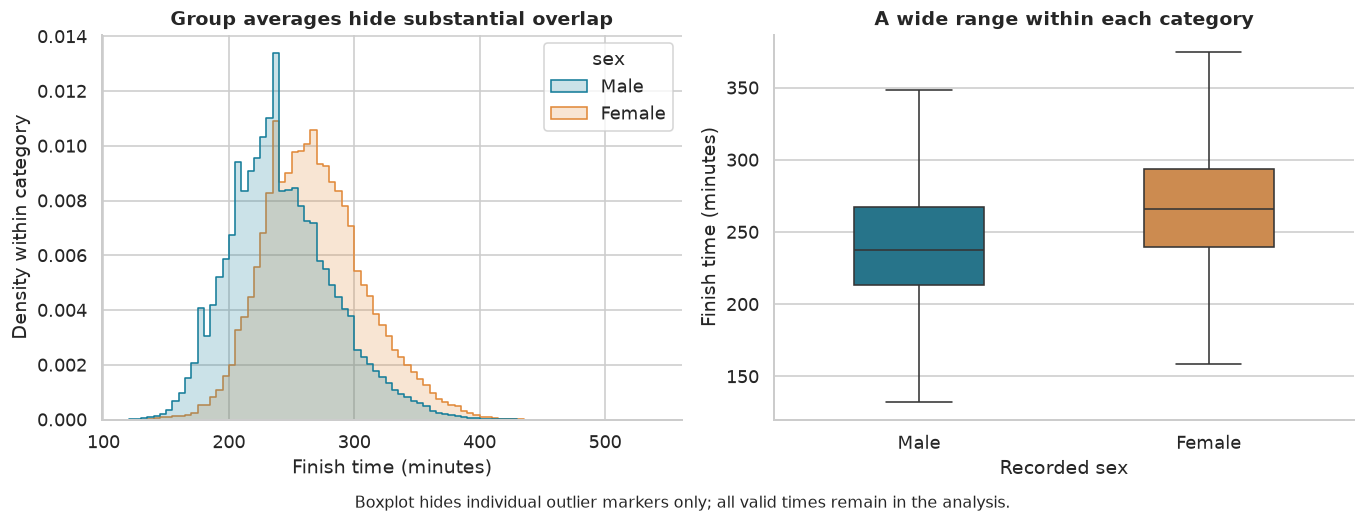

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sns.histplot(data=df, x='minutes', hue='sex', hue_order=['Male','Female'], bins=np.arange(120, 541, 5),
             stat='density', common_norm=False, element='step', fill=True, alpha=.22, ax=axes[0])
axes[0].set(xlabel='Finish time (minutes)', ylabel='Density within category',
            title='Group averages hide substantial overlap')
sns.boxplot(data=df, x='sex', y='minutes', order=['Male','Female'], hue='sex', legend=False,
            showfliers=False, width=.45, ax=axes[1])
axes[1].set(xlabel='Recorded sex', ylabel='Finish time (minutes)', title='A wide range within each category')
fig.text(.5, -.02, 'Boxplot hides individual outlier markers only; all valid times remain in the analysis.', ha='center', fontsize=10)
fig.tight_layout()
save_figure('01_distributions')

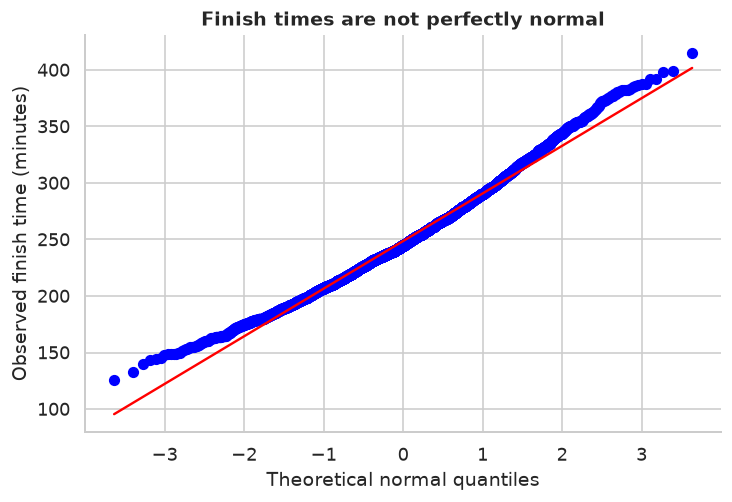

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
stats.probplot(df.minutes.sample(5000, random_state=SEED), dist='norm', plot=ax)
ax.set(title='Finish times are not perfectly normal', xlabel='Theoretical normal quantiles', ylabel='Observed finish time (minutes)')
fig.tight_layout()
save_figure('02_qq_times')

The Q–Q plot compares the shape of finish times with a normal distribution. Tail departures are expected:
finish times cannot be negative, and slower finishes create a long upper tail.
We do not claim that individual times are normal. Inference below is based on annual differences
or annual means, with its own much smaller effective sample size and diagnostics.

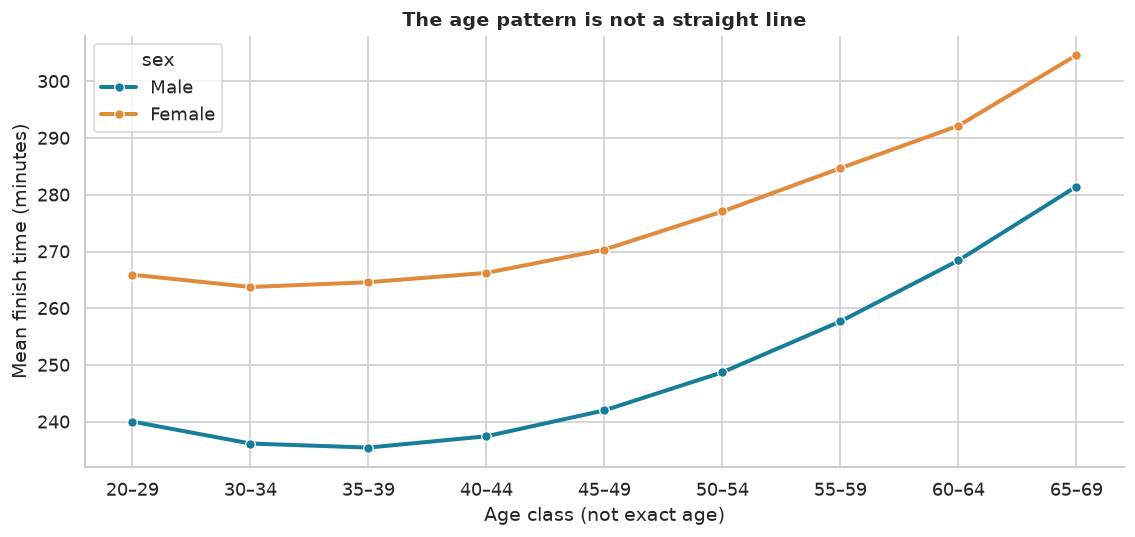

,age_group,sex,n,mean,median
0,20–29,Female,19932,265.919,263.483
1,20–29,Male,50998,240.033,236.917
2,30–34,Female,20493,263.747,260.950
3,30–34,Male,63161,236.165,233.250
4,35–39,Female,22663,264.592,261.433
5,35–39,Male,83621,235.449,232.317
6,40–44,Female,26536,266.233,262.883
7,40–44,Male,96563,237.442,233.933
8,45–49,Female,23176,270.339,267.433
9,45–49,Male,84452,242.004,237.233


In [8]:
age_summary = df.groupby(['age_group', 'sex'], observed=True).minutes.agg(n='size', mean='mean', median='median').reset_index()
save_table(age_summary, 'age_summary')
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.lineplot(data=age_summary, x='age_group', y='mean', hue='sex', hue_order=['Male','Female'],
             marker='o', linewidth=2.5, ax=ax)
ax.set(xlabel='Age class (not exact age)', ylabel='Mean finish time (minutes)',
       title='The age pattern is not a straight line')
fig.tight_layout()
save_figure('03_age_pattern')
display(age_summary)

## 4 · Demographic differences: compare like with like

A raw sex comparison mixes different ages and race years. We first calculate the mean for every
**year × age class × sex** cell. Then:

- For the sex comparison, weight each age class by the same pooled age distribution for both categories.
- For the age comparison, weight each sex by the same pooled sex distribution in every age class.
- Compute each contrast once per year, then estimate the mean of the 20 annual contrasts.

A one-sample t interval/test on annual differences uses 19 degrees of freedom, rather than pretending
all finishes are independent. It assumes annual contrasts are approximately independent and sufficiently
well behaved. These intervals describe variability across comparable race years, not uncertainty about
the arithmetic mean of the already observed records. A Friedman test provides a secondary omnibus check
of age-group ordering with race year as the block.

In [9]:
cell = df.groupby(['YEAR', 'age_group', 'sex'], observed=True).minutes.agg(mean='mean', n='size').reset_index()
age_weights = df.groupby('age_group', observed=True).size() / len(df)
sex_weights = df.sex.value_counts(normalize=True)
cell['age_weight'] = cell.age_group.map(age_weights).astype(float)
cell['sex_weight'] = cell.sex.map(sex_weights)
sex_annual = (cell.assign(value=cell['mean'] * cell.age_weight)
              .groupby(['YEAR','sex']).value.sum().unstack())
sex_annual['female_minus_male'] = sex_annual.Female - sex_annual.Male
age_annual = (cell.assign(value=cell['mean'] * cell.sex_weight)
              .groupby(['YEAR','age_group'], observed=True).value.sum().unstack())
age_difference = age_annual['60–64'] - age_annual['30–34']

def annual_contrast(values, name):
    values = np.asarray(values, dtype=float)
    estimate = values.mean()
    se = stats.sem(values)
    lo, hi = stats.t.interval(.95, df=len(values)-1, loc=estimate, scale=se)
    test = stats.ttest_1samp(values, 0)
    return {'hypothesis':name, 'estimate':estimate, 'ci_low':lo, 'ci_high':hi,
            'p_value':test.pvalue, 'n_years':len(values)}
sex_result = annual_contrast(sex_annual.female_minus_male, 'Female minus male (minutes)')
age_result = annual_contrast(age_difference, 'Age 60–64 minus 30–34 (minutes)')
friedman = stats.friedmanchisquare(*(age_annual[c] for c in age_annual.columns))
save_table(sex_annual.reset_index(), 'annual_sex_contrast')
save_table(age_annual.reset_index(), 'annual_age_means')
display(pd.DataFrame([sex_result, age_result]))
print(f'Secondary age omnibus Friedman statistic = {friedman.statistic:.2f}; p {p_text(friedman.pvalue)}.')

,hypothesis,estimate,ci_low,ci_high,p_value,n_years
0,Female minus male (minutes),27.101,26.269,27.933,0.000,20
1,Age 60–64 minus 30–34 (minutes),30.101,27.738,32.463,0.000,20


Secondary age omnibus Friedman statistic = 155.13; p < 0.001.


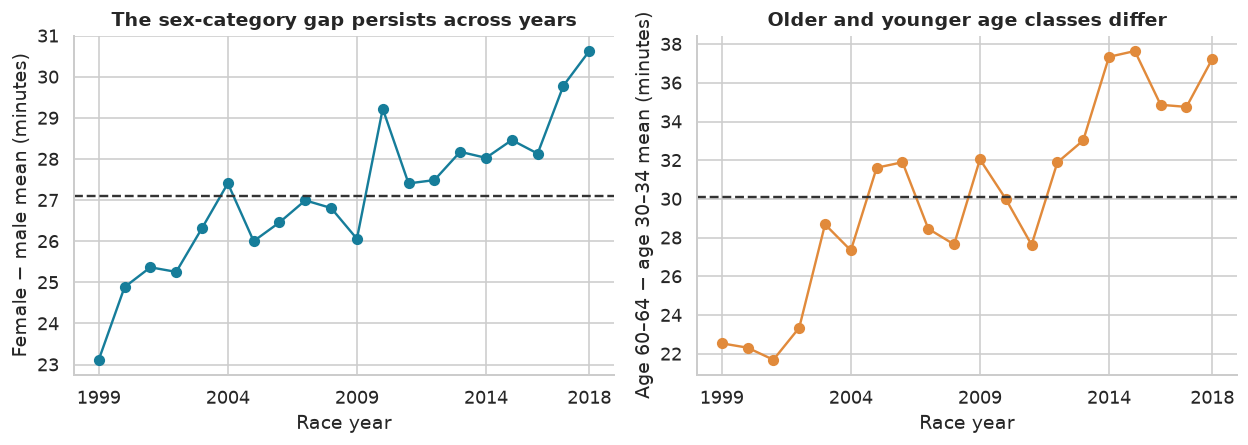

**Magnitude:** the age-standardized female-minus-male difference averages **27.1 minutes** (95% CI 26.3–27.9). The sex-standardized 60–64-minus-30–34 contrast averages **30.1 minutes** (95% CI 27.7–32.5). These are differences between groups of finishers, not changes that an individual would necessarily experience.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sex_annual.index, sex_annual.female_minus_male, 'o-', color='#167d9a')
axes[0].axhline(sex_result['estimate'], linestyle='--', color='#333333')
axes[0].set(title='The sex-category gap persists across years', ylabel='Female − male mean (minutes)', xlabel='Race year')
axes[1].plot(age_difference.index, age_difference, 'o-', color='#e18a3b')
axes[1].axhline(age_result['estimate'], linestyle='--', color='#333333')
axes[1].set(title='Older and younger age classes differ', ylabel='Age 60–64 − age 30–34 mean (minutes)', xlabel='Race year')
for ax in axes:
    ax.set_xticks([1999,2004,2009,2014,2018])
fig.tight_layout()
save_figure('04_annual_contrasts')
display(Markdown(f"**Magnitude:** the age-standardized female-minus-male difference averages **{sex_result['estimate']:.1f} minutes** "
                 f"(95% CI {sex_result['ci_low']:.1f}–{sex_result['ci_high']:.1f}). "
                 f"The sex-standardized 60–64-minus-30–34 contrast averages **{age_result['estimate']:.1f} minutes** "
                 f"(95% CI {age_result['ci_low']:.1f}–{age_result['ci_high']:.1f}). "
                 "These are differences between groups of finishers, not changes that an individual would necessarily experience."))

## 5 · Weather: 20 race days, not hundreds of thousands of experiments

To compare annual finishing times with a stable demographic mix, use direct standardization:

\[
\bar{t}^{\mathrm{std}}_y=\sum_g w_g\bar{t}_{yg},
\]

where \(g\) is an age-class/sex combination and \(w_g\) is its proportion in the pooled primary cohort.
Every year must contain all 18 groups, and weights must sum to 1. This avoids mistaking a change
in the composition of the field for a weather effect. It does not adjust for training, experience,
qualification, equipment, or changes within an age class.

Primary model (one row per year, equal year weights):

\[
\bar{t}^{\mathrm{std}}_y=\beta_0+\beta_T T_y+\beta_Y(y-2009)+\epsilon_y.
\]

\(T_y\) is **mean daily temperature**, not the temperature experienced by an individual runner.
A linear year trend is a limited adjustment for secular change. With only 20 years we keep the model small.
We use HC3 heteroskedasticity-robust standard errors with a t reference distribution (17 residual degrees
of freedom). No full year fixed effects: these would absorb all annual weather variation.

In [11]:
group_weights = df.groupby(['age_group','sex'], observed=True).size() / len(df)
wide = cell.pivot(index='YEAR', columns=['age_group','sex'], values='mean').reindex(columns=group_weights.index)
assert wide.notna().all().all(), 'Do not silently standardize a year with missing demographic cells.'
assert np.isclose(group_weights.sum(), 1)
annual = df.groupby('YEAR').minutes.agg(n='size', raw_mean='mean', median='median').reset_index()
annual['standardized_mean'] = annual.YEAR.map(wide.mul(group_weights, axis=1).sum(axis=1))
annual = annual.merge(weather, on='YEAR', validate='one_to_one')
annual['year_c'] = annual.YEAR - 2009
annual = save_table(annual, 'annual_weather_analysis')
weather_model = smf.ols('standardized_mean ~ AVG_TEMP_C + year_c', data=annual).fit(cov_type='HC3', use_t=True)
lo, hi = weather_model.conf_int().loc['AVG_TEMP_C']
weather_result = {'hypothesis':'Temperature (minutes per 1°C)', 'estimate':weather_model.params['AVG_TEMP_C'],
                  'ci_low':lo, 'ci_high':hi, 'p_value':weather_model.pvalues['AVG_TEMP_C'], 'n_years':len(annual)}
primary_tests = pd.DataFrame([sex_result, age_result, weather_result])
primary_tests['p_holm'] = multipletests(primary_tests.p_value, method='holm')[1]
primary_tests['reject_at_0_05'] = primary_tests.p_holm < .05
save_table(primary_tests, 'primary_tests')
display(annual[['YEAR','n','raw_mean','standardized_mean','AVG_TEMP_C']])
display(primary_tests)
print(weather_model.summary())

,YEAR,n,raw_mean,standardized_mean,AVG_TEMP_C
0,1999,18960,236.176,239.011,15.100
1,2000,22665,247.333,249.603,16.800
2,2001,25616,240.579,242.790,13.000
3,2002,25103,240.869,242.695,12.400
4,2003,30521,245.353,247.074,12.000
5,2004,27804,243.160,244.660,10.800
6,2005,30163,250.641,251.872,15.800
7,2006,29944,255.976,256.682,19.400
8,2007,32227,246.717,247.472,13.100
9,2008,35409,246.747,247.061,11.300


,hypothesis,estimate,ci_low,ci_high,p_value,n_years,p_holm,reject_at_0_05
0,Female minus male (minutes),27.101,26.269,27.933,0.000,20,0.000,True
1,Age 60–64 minus 30–34 (minutes),30.101,27.738,32.463,0.000,20,0.000,True
2,Temperature (minutes per 1°C),1.291,0.833,1.749,0.000,20,0.000,True


                            OLS Regression Results                            
Dep. Variable:      standardized_mean   R-squared:                       0.687
Model:                            OLS   Adj. R-squared:                  0.650
Method:                 Least Squares   F-statistic:                     20.17
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.25e-05
Time:                        00:56:11   Log-Likelihood:                -45.746
No. Observations:                  20   AIC:                             97.49
Df Residuals:                      17   BIC:                             100.5
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    230.5677      2.693     85.620      0.0

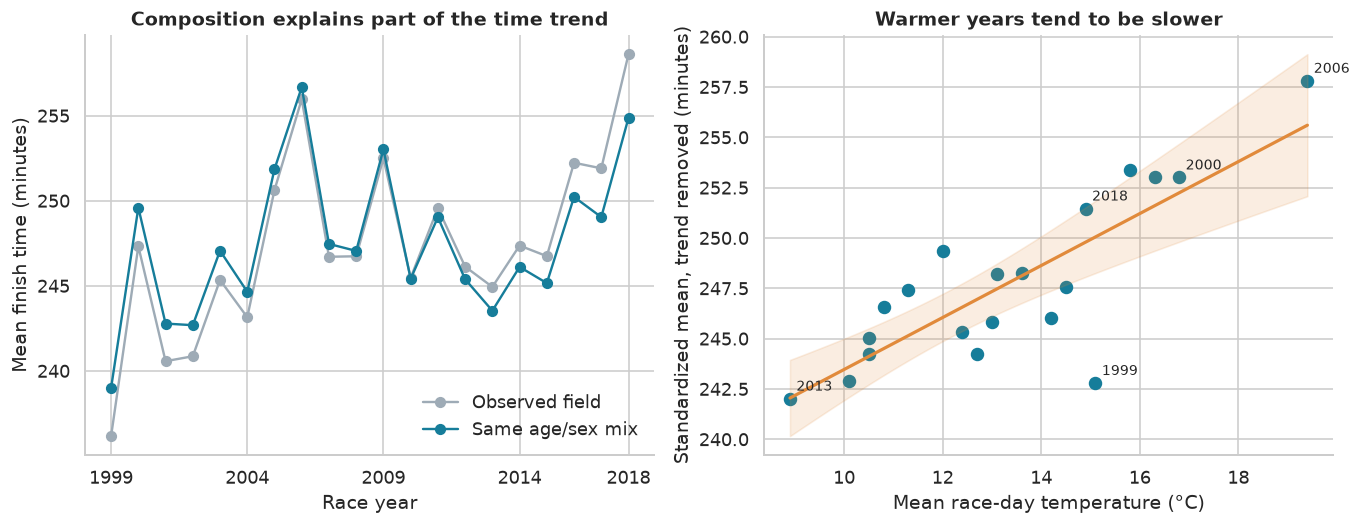

The fitted association is **1.29 minutes per 1°C** (95% CI 0.83–1.75). A 5°C difference corresponds to **6.5 minutes** in the standardized annual mean, within the observed temperature range. This is an association, not a personal pacing formula or a causal estimate.

In [12]:
# Remove the estimated calendar trend for a two-dimensional weather display.
annual['trend_adjusted_mean'] = annual.standardized_mean - weather_model.params['year_c'] * annual.year_c
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(annual.YEAR, annual.raw_mean, 'o-', label='Observed field', color='#9eabb6')
axes[0].plot(annual.YEAR, annual.standardized_mean, 'o-', label='Same age/sex mix', color='#167d9a')
axes[0].set(title='Composition explains part of the time trend', xlabel='Race year', ylabel='Mean finish time (minutes)')
axes[0].legend(frameon=False)
axes[0].set_xticks([1999, 2004, 2009, 2014, 2018])
axes[1].scatter(annual.AVG_TEMP_C, annual.trend_adjusted_mean, color='#167d9a', s=55)
# Label only selected years so the figure remains readable; the full table is above.
for _, row in annual.loc[annual.YEAR.isin([1999,2000,2006,2013,2018])].iterrows():
    axes[1].annotate(str(int(row.YEAR)), (row.AVG_TEMP_C,row.trend_adjusted_mean),
                     xytext=(4,5), textcoords='offset points', fontsize=9)
grid = pd.DataFrame({'AVG_TEMP_C':np.linspace(annual.AVG_TEMP_C.min(),annual.AVG_TEMP_C.max(),100), 'year_c':0})
pred_grid = weather_model.get_prediction(grid).summary_frame()
axes[1].plot(grid.AVG_TEMP_C, pred_grid['mean'], color='#e18a3b', linewidth=2)
axes[1].fill_between(grid.AVG_TEMP_C, pred_grid.mean_ci_lower, pred_grid.mean_ci_upper, color='#e18a3b',alpha=.15)
axes[1].set(title='Warmer years tend to be slower', xlabel='Mean race-day temperature (°C)',
            ylabel='Standardized mean, trend removed (minutes)')
fig.tight_layout()
save_figure('05_weather')
display(Markdown(f"The fitted association is **{weather_result['estimate']:.2f} minutes per 1°C** "
                 f"(95% CI {lo:.2f}–{hi:.2f}). A 5°C difference corresponds to "
                 f"**{5*weather_result['estimate']:.1f} minutes** in the standardized annual mean, "
                 "within the observed temperature range. This is an association, not a personal pacing formula or a causal estimate."))

### Other weather variables: exploratory, not a search for the smallest p-value

The three temperature measures are related. We do not put all of them in a 20-row model and interpret
unstable coefficients. Below are annual Pearson correlations between the standardized outcome and each
available weather measure. They are descriptive and do not control for calendar time.
Precipitation is **not** relative humidity. The `CLOUD_hrs` label is retained from the source and is not
used to make physical claims because its measurement definition is unclear.

,variable,pearson_r,unadjusted_p,n_years
0,AVG_TEMP_C,0.661,0.002,20
1,MAX_TEMP_C,0.791,0.000,20
2,MIN_TEMP_C,0.165,0.487,20
3,PRECIP_mm,-0.176,0.458,20
4,SUNSHINE_hrs,0.559,0.010,20
5,ATMOS_PRESS_mbar,0.109,0.646,20


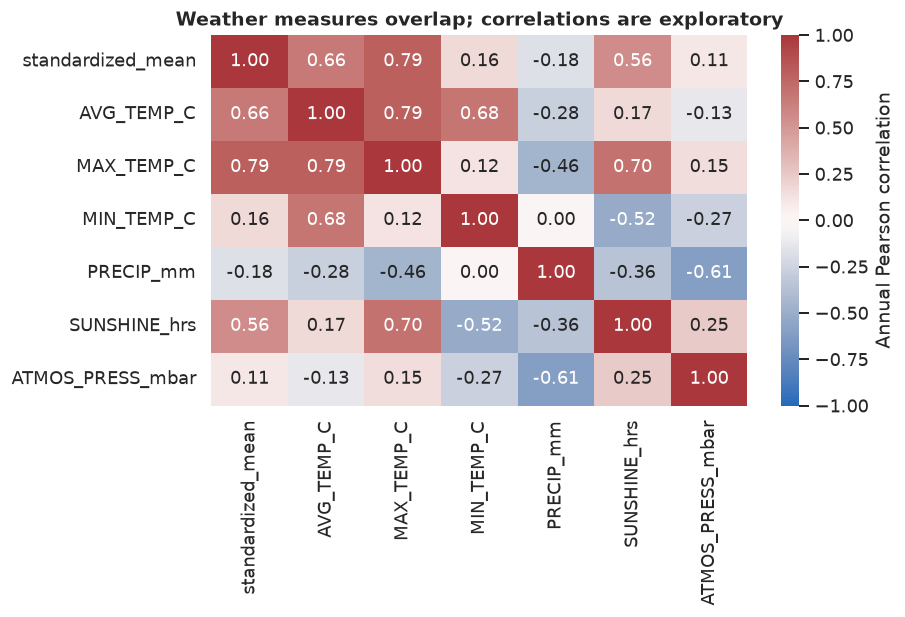

In [13]:
weather_columns = ['AVG_TEMP_C','MAX_TEMP_C','MIN_TEMP_C','PRECIP_mm','SUNSHINE_hrs','ATMOS_PRESS_mbar']
correlations = []
for col in weather_columns:
    result = stats.pearsonr(annual[col], annual.standardized_mean)
    correlations.append({'variable':col, 'pearson_r':result.statistic, 'unadjusted_p':result.pvalue, 'n_years':len(annual)})
correlations = save_table(pd.DataFrame(correlations), 'exploratory_correlations')
display(correlations)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(annual[['standardized_mean']+weather_columns].corr(), annot=True, fmt='.2f', cmap='vlag',
            vmin=-1,vmax=1, center=0, ax=ax, cbar_kws={'label':'Annual Pearson correlation'})
ax.set_title('Weather measures overlap; correlations are exploratory')
fig.tight_layout()
save_figure('06_correlations')

## 6 · Does the temperature finding survive reasonable changes?

We check: no calendar trend; a quadratic trend; adding precipitation; extending ages to 84 (pooling ages 65–84 to avoid empty cells);
trimming the outer 1% of finish times; restricting the era to 2005–2018; and allowing lag-1 serial
correlation in errors (HAC). These are sensitivity analyses, not competing models from which we select
the most significant. Leave-one-year-out refits show whether a single weather day drives the slope.
Diagnostics concern the 20 annual residuals, not the hundreds of thousands of runner rows.

In [14]:
def standardized_annual(subset):
    weights = subset.groupby(['age_code','GENDER']).size() / len(subset)
    means = subset.groupby(['YEAR','age_code','GENDER']).minutes.mean().unstack(['age_code','GENDER'])
    means = means.reindex(columns=weights.index)
    assert means.notna().all().all()
    out = means.mul(weights, axis=1).sum(axis=1).rename('standardized_mean').reset_index()
    out = out.merge(weather, on='YEAR', validate='one_to_one')
    out['year_c'] = out.YEAR - 2009
    return out

primary_formula = 'standardized_mean ~ AVG_TEMP_C + year_c'
trim_lo, trim_hi = df.minutes.quantile([.01,.99])
extended = work.loc[work.YEAR.between(1999,2018) & work.age_code.isin(list(AGE_LABELS)+[70,75,80])
                    & work.minutes.gt(0) & work.GENDER.isin(['male','female'])].copy()
# Rare older categories have empty year/sex cells; combine them before standardizing.
extended['age_code'] = extended.age_code.clip(upper=65)
specifications = [
    ('Primary: age 20–69, linear trend', annual, primary_formula),
    ('No calendar trend', annual, 'standardized_mean ~ AVG_TEMP_C'),
    ('Quadratic calendar trend', annual, primary_formula+' + I(year_c**2)'),
    ('Add daily precipitation', annual, primary_formula+' + PRECIP_mm'),
    ('Include 70–84, pooled with 65–69', standardized_annual(extended), primary_formula),
    ('Trim outer 1% of finish times', standardized_annual(df.loc[df.minutes.between(trim_lo,trim_hi)]), primary_formula),
    ('Later period: 2005–2018', standardized_annual(df.loc[df.YEAR.ge(2005)]), primary_formula)
]
sensitivity_rows = []
for name, data, formula in specifications:
    fit = smf.ols(formula, data=data).fit(cov_type='HC3', use_t=True)
    limits = fit.conf_int().loc['AVG_TEMP_C']
    sensitivity_rows.append({'specification':name, 'slope':fit.params['AVG_TEMP_C'],
                             'ci_low':limits.iloc[0], 'ci_high':limits.iloc[1], 'n_years':len(data)})
hac = smf.ols(primary_formula, data=annual).fit(cov_type='HAC', cov_kwds={'maxlags':1,'use_correction':True}, use_t=True)
hac_ci = hac.conf_int().loc['AVG_TEMP_C']
sensitivity_rows.append({'specification':'Primary, lag-1 HAC errors', 'slope':hac.params['AVG_TEMP_C'],
                         'ci_low':hac_ci.iloc[0], 'ci_high':hac_ci.iloc[1], 'n_years':len(annual)})
sensitivity = save_table(pd.DataFrame(sensitivity_rows), 'weather_sensitivity')
loo_rows = []
for year in annual.YEAR:
    fit = smf.ols(primary_formula, data=annual.loc[annual.YEAR.ne(year)]).fit()
    loo_rows.append({'omitted_year':int(year), 'slope':fit.params['AVG_TEMP_C']})
loo = save_table(pd.DataFrame(loo_rows), 'leave_one_year_out')
display(sensitivity)
print(f'Leave-one-year-out temperature slopes: {loo.slope.min():.2f} to {loo.slope.max():.2f} min/°C.')

,specification,slope,ci_low,ci_high,n_years
0,"Primary: age 20–69, linear trend",1.291,0.833,1.749,20
1,No calendar trend,1.098,0.537,1.659,20
2,Quadratic calendar trend,1.423,1.138,1.709,20
3,Add daily precipitation,1.336,0.868,1.803,20
4,"Include 70–84, pooled with 65–69",1.290,0.833,1.748,20
5,Trim outer 1% of finish times,1.174,0.739,1.608,20
6,Later period: 2005–2018,1.349,0.995,1.704,14
7,"Primary, lag-1 HAC errors",1.291,0.909,1.673,20


Leave-one-year-out temperature slopes: 1.14 to 1.35 min/°C.


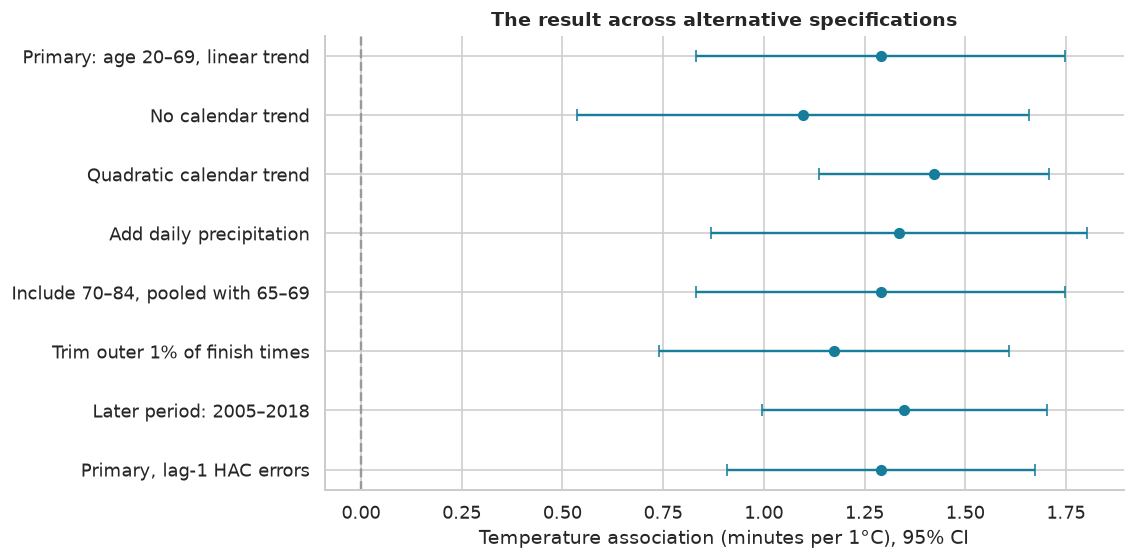

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(sensitivity))
ax.errorbar(sensitivity.slope, y, xerr=[sensitivity.slope-sensitivity.ci_low,
                                      sensitivity.ci_high-sensitivity.slope], fmt='o', color='#167d9a', capsize=4)
ax.axvline(0,color='#999999',linestyle='--')
ax.set_yticks(y, sensitivity.specification)
ax.invert_yaxis()
ax.set(xlabel='Temperature association (minutes per 1°C), 95% CI', title='The result across alternative specifications')
fig.tight_layout()
save_figure('07_sensitivity')

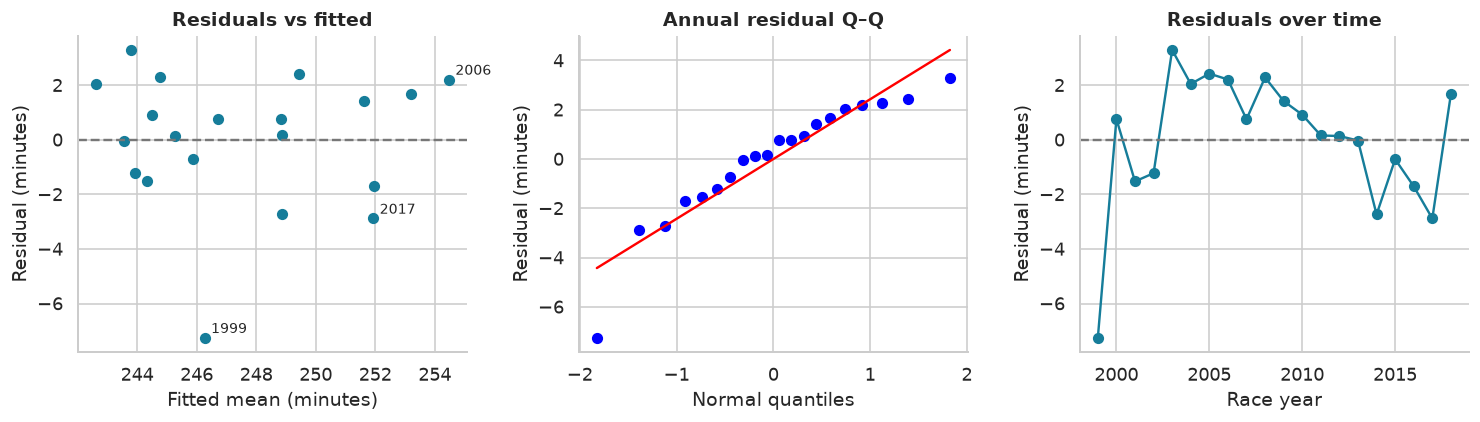

Largest Cook distances (not automatic exclusions):


,YEAR,fitted,residual,cooks_distance,leverage
0,1999,246.268,-7.257,0.770,0.192
7,2006,254.473,2.209,0.184,0.334
18,2017,251.931,-2.884,0.114,0.183


In [16]:
ordinary_fit = smf.ols(primary_formula, data=annual).fit()
influence = ordinary_fit.get_influence()
diagnostics = annual[['YEAR']].copy()
diagnostics['fitted'] = ordinary_fit.fittedvalues
diagnostics['residual'] = ordinary_fit.resid
diagnostics['cooks_distance'] = influence.cooks_distance[0]
diagnostics['leverage'] = influence.hat_matrix_diag
save_table(diagnostics, 'annual_diagnostics')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(diagnostics.fitted, diagnostics.residual, color='#167d9a')
axes[0].axhline(0,color='#777777',linestyle='--')
for _, row in diagnostics.nlargest(3,'cooks_distance').iterrows():
    axes[0].annotate(str(int(row.YEAR)), (row.fitted,row.residual), xytext=(4,3),textcoords='offset points',fontsize=9)
axes[0].set(title='Residuals vs fitted',xlabel='Fitted mean (minutes)',ylabel='Residual (minutes)')
stats.probplot(ordinary_fit.resid,dist='norm',plot=axes[1])
axes[1].set(title='Annual residual Q–Q',xlabel='Normal quantiles',ylabel='Residual (minutes)')
axes[2].plot(annual.YEAR,ordinary_fit.resid,'o-',color='#167d9a')
axes[2].axhline(0,color='#777777',linestyle='--')
axes[2].set(title='Residuals over time',xlabel='Race year',ylabel='Residual (minutes)')
fig.tight_layout()
save_figure('08_diagnostics')
print('Largest Cook distances (not automatic exclusions):')
display(diagnostics.nlargest(3,'cooks_distance'))

### Exploratory age–temperature interaction

Does the older-minus-younger mean-time gap change in warmer years? Regress the annual standardized
60–64-minus-30–34 contrast on temperature and year. This is a secondary analysis with only 20 years;
a wide interval cannot establish that age groups respond equally. It does not measure individual
heat tolerance or account for acclimatization.

In [17]:
interaction_data = annual[['YEAR','AVG_TEMP_C','year_c']].copy()
interaction_data['age_gap'] = interaction_data.YEAR.map(age_difference)
interaction_model = smf.ols('age_gap ~ AVG_TEMP_C + year_c',interaction_data).fit(cov_type='HC3',use_t=True)
interaction_ci = interaction_model.conf_int().loc['AVG_TEMP_C']
interaction_result = {'slope':interaction_model.params['AVG_TEMP_C'], 'ci_low':interaction_ci.iloc[0],
                      'ci_high':interaction_ci.iloc[1], 'p_value':interaction_model.pvalues['AVG_TEMP_C']}
display(pd.DataFrame([interaction_result]))

,slope,ci_low,ci_high,p_value
0,0.221,-0.263,0.705,0.348


## 7 · Can we predict a runner's finish in a future race?

A significant group association does not guarantee a useful individual prediction.
We train on **1999–2013** and evaluate once on **2014–2018**. All five test years are excluded from fitting.
The feature sets are fixed before evaluating the test set, with no test-driven tuning.

Models are deliberately interpretable: a training-mean baseline; age-class × sex group means;
groups plus a linear calendar trend; and groups plus trend and temperature.
We also remove sex or age from the full model to compare predictive contributions on the same test rows.
The full interaction group accounts for different age patterns by recorded sex.

All encoding and coefficients are learned on training data only. Calendar year and daily weather are
known here retrospectively. This is **prediction conditional on observed weather**, not an operational
pre-race weather forecast. There are no split times, final ranks, or other variables derived from finish time.
Unidentified returning runners can occur across years, so the split tests a future race, not necessarily a new person.

**MAE** is the average absolute error in minutes. **RMSE** penalizes large misses more.
**R²** compares squared error with predicting the test-set mean; negative values are possible.
Report every model and every held-out year. Do not choose a winner from this test set and call it validated.

In [18]:
train = df.loc[df.YEAR.le(2013)].copy()
test = df.loc[df.YEAR.ge(2014)].copy()
assert set(train.YEAR).isdisjoint(test.YEAR)
print(f'Training: {len(train):,} finishes, {train.YEAR.min()}–{train.YEAR.max()}')
print(f'Test: {len(test):,} finishes, {test.YEAR.min()}–{test.YEAR.max()}')

model_specs = {
    'Training mean': ([], []),
    'Age + sex': (['group'], []),
    'Age + sex + year': (['group'], ['year_c']),
    'Age + sex + year + temperature': (['group'], ['year_c','AVG_TEMP_C']),
    'Full without sex': (['age_group'], ['year_c','AVG_TEMP_C']),
    'Full without age': (['sex'], ['year_c','AVG_TEMP_C'])
}
predictions = {}
metric_rows, year_metric_rows = [], []
for name, (categorical, numeric) in model_specs.items():
    if not categorical and not numeric:
        model = DummyRegressor(strategy='mean')
        model.fit(np.zeros((len(train),1)),train.minutes)
        prediction = model.predict(np.zeros((len(test),1)))
    else:
        encoder = ColumnTransformer([
            ('categories',OneHotEncoder(drop='first',handle_unknown='error'),categorical),
            ('numeric','passthrough',numeric)
        ])
        model = make_pipeline(encoder,LinearRegression())
        model.fit(train[categorical+numeric],train.minutes)
        prediction = model.predict(test[categorical+numeric])
    predictions[name] = prediction
    metric_rows.append({'model':name,'mae':mean_absolute_error(test.minutes,prediction),
                        'rmse':np.sqrt(mean_squared_error(test.minutes,prediction)),
                        'r2':r2_score(test.minutes,prediction)})
    for year in sorted(test.YEAR.unique()):
        mask = test.YEAR.eq(year).to_numpy()
        year_metric_rows.append({'model':name,'year':int(year),'n':int(mask.sum()),
                                'mae':mean_absolute_error(test.minutes.to_numpy()[mask],prediction[mask]),
                                'bias_pred_minus_actual':float((prediction[mask]-test.minutes.to_numpy()[mask]).mean())})
metrics = save_table(pd.DataFrame(metric_rows),'prediction_metrics')
year_metrics = save_table(pd.DataFrame(year_metric_rows),'prediction_by_year')
display(metrics)
display(year_metrics.pivot(index='year',columns='model',values='mae'))

Training: 449,530 finishes, 1999–2013
Test: 180,015 finishes, 2014–2018


,model,mae,rmse,r2
0,Training mean,36.730,46.663,-0.012
1,Age + sex,34.392,43.707,0.112
2,Age + sex + year,34.461,43.655,0.114
3,Age + sex + year + temperature,34.863,43.633,0.115
4,Full without sex,36.435,45.435,0.040
5,Full without age,35.809,44.744,0.069


model,Age + sex,Age + sex + year,Age + sex + year + temperature,Full without age,Full without sex,Training mean
year,,,,,,
2014,32.265,32.378,32.754,33.752,34.281,34.388
2015,32.790,32.935,32.794,33.818,34.372,34.929
2016,34.459,34.515,35.173,36.061,36.617,36.627
2017,34.084,34.169,34.951,35.783,36.556,36.418
2018,37.589,37.556,37.874,38.872,39.552,40.412


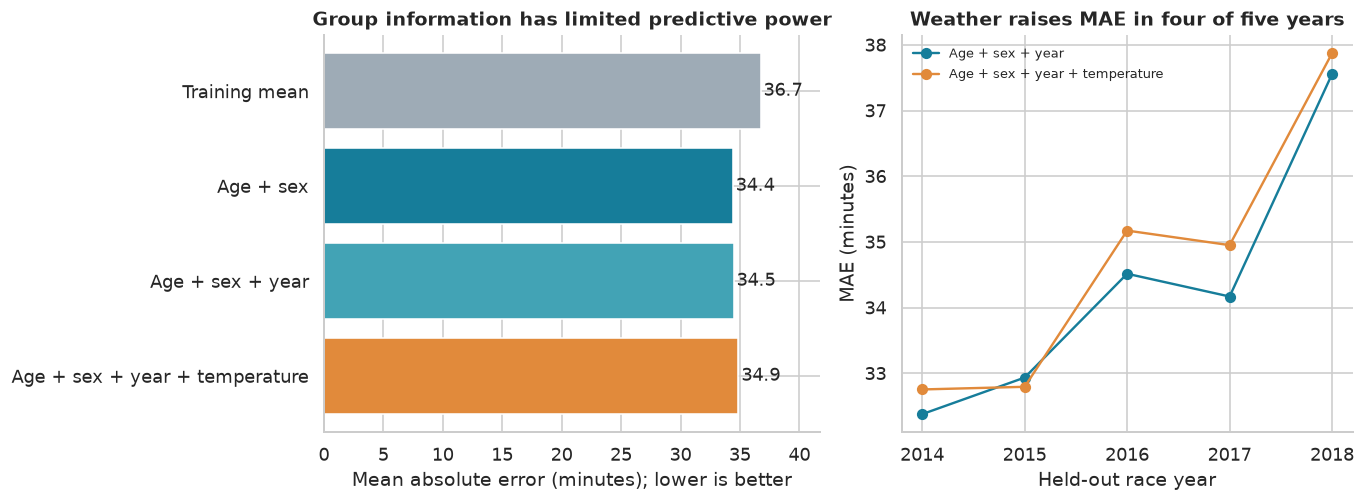

Adding temperature changes pooled MAE by +0.402 minutes (negative is better).
Full-model improvement over baseline: 5.1%.


In [19]:
full_name = 'Age + sex + year + temperature'
base_mae = metrics.set_index('model').loc['Training mean','mae']
full_mae = metrics.set_index('model').loc[full_name,'mae']
no_weather_mae = metrics.set_index('model').loc['Age + sex + year','mae']
fig, axes = plt.subplots(1,2,figsize=(12,4.5),gridspec_kw={'width_ratios':[1.1,1]})
show_metrics = metrics.iloc[:4]
axes[0].barh(show_metrics.model,show_metrics.mae,color=['#9eabb6','#167d9a','#42a3b5','#e18a3b'])
axes[0].invert_yaxis()
axes[0].set(xlabel='Mean absolute error (minutes); lower is better',title='Group information has limited predictive power')
for i, value in enumerate(show_metrics.mae):
    axes[0].text(value+.25,i,f'{value:.1f}',va='center')
axes[0].set_xlim(0,show_metrics.mae.max()+5)
for name,color in [('Age + sex + year','#167d9a'),(full_name,'#e18a3b')]:
    data = year_metrics.loc[year_metrics.model.eq(name)]
    axes[1].plot(data.year,data.mae,'o-',label=name,color=color)
axes[1].set(xlabel='Held-out race year',ylabel='MAE (minutes)',title='Weather raises MAE in four of five years',xticks=range(2014,2019))
axes[1].legend(fontsize=8,frameon=False)
fig.tight_layout()
save_figure('09_prediction')
print(f'Adding temperature changes pooled MAE by {full_mae-no_weather_mae:+.3f} minutes (negative is better).')
print(f'Full-model improvement over baseline: {100*(base_mae-full_mae)/base_mae:.1f}%.')

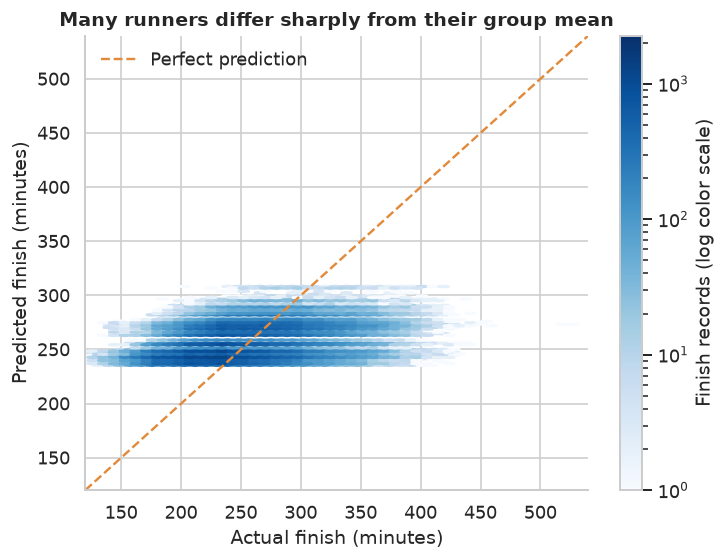

In [20]:
# Actual versus predicted, with every held-out row contributing to a density plot.
fig, ax = plt.subplots(figsize=(6.5,5))
hb = ax.hexbin(test.minutes,predictions[full_name],gridsize=45,mincnt=1,bins='log',cmap='Blues')
ax.plot([120,540],[120,540],'--',color='#e18a3b',label='Perfect prediction')
ax.set(xlabel='Actual finish (minutes)',ylabel='Predicted finish (minutes)',
       title='Many runners differ sharply from their group mean',xlim=(120,540),ylim=(120,540))
fig.colorbar(hb,ax=ax,label='Finish records (log color scale)')
ax.legend(frameon=False)
fig.tight_layout()
save_figure('10_actual_predicted')

## 8 · What the evidence can—and cannot—say

The demographic contrasts describe the people who finished these races. They cannot isolate the effects of
aging, sex, training, participation barriers, or experience. The temperature model compares years in one
city and adjusts for only a fixed demographic mix and a simple trend. Race organization, timing conventions,
course changes, wind, humidity, and unmeasured changes in the entrants remain potential confounders.
No runner identifier is available; finish records should never be described as unique people.

The modern analysis period contains only **20 weather observations**. Robust standard errors and sensitivity
checks help assess stability but cannot remove unmeasured confounding. Finisher-only data cannot quantify
weather's association with withdrawal or failure to finish. The estimates do not identify causal effects.

The Berlin-only humidity hypothesis remains unanswered. Chapter 9 adds a Chicago humidity estimate;
Chapters 12–13 add previous-race records and a home-weather proxy. Actual training exposure and
harmonized route-level weather remain unmeasured. K-means is omitted because creating
performance labels from finish time would not answer the central questions.

In [21]:
sex_holm, age_holm, weather_holm = primary_tests.p_holm.to_list()
full_r2 = metrics.set_index('model').loc[full_name,'r2']
display(Markdown(f"""
### Results in plain language

- **Demographics:** the age-standardized female-minus-male difference is {sex_result['estimate']:.1f} minutes;
  the sex-standardized 60–64-minus-30–34 difference is {age_result['estimate']:.1f} minutes.
  Holm-adjusted p-values are {sex_holm:.3g} and {age_holm:.3g}. The overlapping distributions matter as much as the averages.
- **Temperature:** a 5°C warmer day is associated with {5*weather_result['estimate']:.1f} additional minutes
  in the standardized annual mean (95% CI {5*weather_result['ci_low']:.1f}–{5*weather_result['ci_high']:.1f});
  Holm-adjusted p {p_text(weather_holm)}. Leave-one-year-out slopes range from {loo.slope.min():.2f} to {loo.slope.max():.2f} min/°C.
- **Prediction:** the full model misses individual finish times by {full_mae:.1f} minutes on average
  in 2014–2018 (R² = {full_r2:.3f}), compared with {base_mae:.1f} minutes for the training-mean baseline.
  Adding weather changes MAE by {full_mae-no_weather_mae:+.2f} minutes compared with the same model without temperature (positive means worse).
- **Humidity in Berlin:** unmeasured; the Chicago extension below adds a derived humidity analysis.

These data support meaningful group patterns while leaving much of individual performance unexplained.
"""))


### Results in plain language

- **Demographics:** the age-standardized female-minus-male difference is 27.1 minutes;
  the sex-standardized 60–64-minus-30–34 difference is 30.1 minutes.
  Holm-adjusted p-values are 1.06e-23 and 3.22e-16. The overlapping distributions matter as much as the averages.
- **Temperature:** a 5°C warmer day is associated with 6.5 additional minutes
  in the standardized annual mean (95% CI 4.2–8.7);
  Holm-adjusted p < 0.001. Leave-one-year-out slopes range from 1.14 to 1.35 min/°C.
- **Prediction:** the full model misses individual finish times by 34.9 minutes on average
  in 2014–2018 (R² = 0.115), compared with 36.7 minutes for the training-mean baseline.
  Adding weather changes MAE by +0.40 minutes compared with the same model without temperature (positive means worse).
- **Humidity in Berlin:** unmeasured; the Chicago extension below adds a derived humidity analysis.

These data support meaningful group patterns while leaving much of individual performance unexplained.


### Export a reproducible evidence bundle

All figures and tables above are saved in `outputs/`. This cell saves a compact JSON result summary
for the separate narrative report. The report is rendered from these calculated results, not manually
invented numbers. Dependencies, source hashes, and a local download script support reproduction.

In [22]:
summary = {
    'n_raw':len(raw), 'n_analysis':len(df), 'n_years':int(df.YEAR.nunique()),
    'n_2019_male_only':int(raw.YEAR.eq(2019).sum()),
    'n_train':len(train), 'n_test':len(test), 'mean_minutes':float(df.minutes.mean()),
    'median_minutes':float(df.minutes.median()),
    'p10':float(df.minutes.quantile(.1)), 'p90':float(df.minutes.quantile(.9)),
    'temperature_min':float(annual.AVG_TEMP_C.min()), 'temperature_max':float(annual.AVG_TEMP_C.max()),
    'primary_tests':primary_tests.to_dict(orient='records'),
    'prediction_metrics':metrics.to_dict(orient='records'),
    'sensitivity':sensitivity.to_dict(orient='records'),
    'loo_slope_min':float(loo.slope.min()), 'loo_slope_max':float(loo.slope.max()),
    'interaction':interaction_result, 'friedman_p':float(friedman.pvalue),
    'raw_trend_change':float(annual.raw_mean.iloc[-1]-annual.raw_mean.iloc[0]),
    'standardized_trend_change':float(annual.standardized_mean.iloc[-1]-annual.standardized_mean.iloc[0]),
    'source':manifest,
    'environment':{'python':platform.python_version(), **{name:importlib.metadata.version(name)
                   for name in ['pandas','numpy','scipy','matplotlib','seaborn','statsmodels','scikit-learn','nbformat']}}
}
(OUT / 'results.json').write_text(json.dumps(summary,indent=2,default=float)+'\n')
# Regenerate the self-contained narrative from this run's figures and numbers.
import runpy
runpy.run_path(str(ROOT / 'scripts' / 'render_berlin_report.py'), run_name='__main__')
print('Saved Berlin outputs/results.json and berlin_story.html.')

Rendered berlin_story.html with embedded figures.
Saved Berlin outputs/results.json and berlin_story.html.


### Sources and methods references

- [Kaggle: Berlin marathon data, version 2](https://www.kaggle.com/datasets/aiaiaidavid/berlin-marathons-data) — raw results, weather, license and attribution.
- [Primary research: Elite Marathoners Run Faster With Increasing Temperatures in Berlin Marathon](https://pmc.ncbi.nlm.nih.gov/articles/PMC8293098/) — collection context; our analysis concerns the broader field, not just elite runners.
- [Berlin results API age-class documentation](https://github.com/hmelberg/berlin-marathon#age-classes) — age-code interpretation.
- [Statsmodels robust covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html) — HC3 and HAC implementation.
- [Scikit-learn regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics) — MAE, RMSE and R² definitions.

All numerical findings in this notebook are calculated from the downloaded source. External research is
context and provenance, not a substitute for this project's results.

# 9 · Beyond Berlin: independent events and complementary measurements

The original analysis used one source. This extension analyzes **four additional results/weather datasets**, followed by real training logs in Chapter 15,
and audits a fifth candidate. It expands the questions rather than merely adding more rows.
All extensions are **exploratory**, planned after reviewing the source schemas and some preliminary summaries.
We report uncertainty, competing specifications, and null findings. No synthetic data are used.

| Kaggle source | Role | Important restriction |
|---|---|---|
| [Chicago results v3](https://www.kaggle.com/datasets/runningwithrock/chicago-marathon-results) | Replicate heat association; add estimated humidity and wind | Age codes are group upper boundaries; 2007 race halted |
| [U.S. fall marathons v1](https://www.kaggle.com/datasets/runningwithrock/2010-2019-fall-marathons) | Compare fields across races | Fall races with ≥500 finishers, not a random sample of all races |
| [Boston 2015–2017 v4](https://www.kaggle.com/datasets/rojour/boston-results) | Pacing, checkpoint prediction, previous-race history | Missing splits; no universal runner identifier |
| [Boston 2024 weather/splits v2](https://www.kaggle.com/datasets/runningwithrock/2024-boston-marathon-weather-and-splits) | Home-weather proxy and slowdown | U.S. runners with ZIP codes only |
| [Training pilot v2](https://www.kaggle.com/datasets/girardi69/marathon-time-predictions) | Data-quality/leakage audit only | 87 rows; mileage includes the race; ambiguous speed/time fields |

**Do not sum these source counts into a count of unique people or unique finishes.** Chicago 2010–2019
overlaps the fall dataset; Boston runners can recur; Berlin may include the same people too.
The datasets support separate analyses. They are never stacked into one unexamined regression.
Running with Rock supplied three of the additional datasets; different events are not necessarily
independent data-collection pipelines. Attribution and source licenses are preserved in the manifests.

In [23]:
EXP = OUT / 'expanded'
ET = EXP / 'tables'
EF = EXP / 'figures'
for folder in [ET, EF]:
    folder.mkdir(parents=True, exist_ok=True)

def etable(frame, name, index=False):
    frame.to_csv(ET / f'{name}.csv', index=index)
    return frame

def efigure(name):
    plt.savefig(EF / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def coefficient(fit, term, question, scale=1):
    ci = fit.conf_int().loc[term]
    return {'question':question, 'estimate':float(fit.params[term]*scale),
            'ci_low':float(ci.iloc[0]*scale), 'ci_high':float(ci.iloc[1]*scale),
            'p_value':float(fit.pvalues[term])}

source_rows = []
for name in ['chicago','fall_marathons','boston_2015_2017','boston_2024','training_pilot']:
    folder = ROOT / 'data' / 'raw' / name
    info = json.loads((folder / 'manifest.json').read_text())
    for filename, expected in info['files'].items():
        assert hashlib.sha256((folder / filename).read_bytes()).hexdigest() == expected
    source_rows.append({'source':name,'dataset':info['dataset'],'version':info['version'],
                        'license':info['license_as_listed'],'url':info['url']})
source_catalog = etable(pd.DataFrame(source_rows), 'source_catalog')
display(source_catalog)
selection_decisions = {
    'runningwithrock/chicago-marathon-results':('Analyze','Second long event series; adds dew point and wind'),
    'runningwithrock/2010-2019-fall-marathons':('Analyze','Cross-race field comparisons; audit overlap with Chicago'),
    'rojour/boston-results':('Analyze','Splits and conservative historical linkage'),
    'runningwithrock/2024-boston-marathon-weather-and-splits':('Analyze','Home-weather proxy; pre-race date and ZIP audit'),
    'girardi69/marathon-time-predictions':('Audit only','Tiny sample; mileage includes race; speed anomaly; missing training fields'),
    'likithagedipudi/run-club-marathon-performance-dataset':('Exclude','Publisher explicitly describes synthetic generation'),
    'runningwithrock/nyc-marathon-results-all-years':('Not selected','Adds historical coverage but no weather; overlaps fall sample'),
    'runningwithrock/2024-marathon-results':('Not selected','Adds recency; not the missing training or weather measurements'),
    'mexwell/long-distance-running-dataset':('Analyze','Real training logs; supplementary race-day duration proxy, not official finish times')
}
selection = pd.DataFrame([{'dataset':ref,'decision':decision,'reason':reason}
                          for ref,(decision,reason) in selection_decisions.items()])
etable(selection,'dataset_selection')
expansion_audit = []

,source,dataset,version,license,url
0,chicago,runningwithrock/chicago-marathon-results,3,MIT,https://www.kaggle.com/datasets/runningwithroc...
1,fall_marathons,runningwithrock/2010-2019-fall-marathons,1,MIT,https://www.kaggle.com/datasets/runningwithroc...
2,boston_2015_2017,rojour/boston-results,4,Unknown,https://www.kaggle.com/datasets/rojour/boston-...
3,boston_2024,runningwithrock/2024-boston-marathon-weather-a...,2,Attribution 4.0 International (CC BY 4.0),https://www.kaggle.com/datasets/runningwithroc...
4,training_pilot,girardi69/marathon-time-predictions,2,CC0: Public Domain,https://www.kaggle.com/datasets/girardi69/mara...


## 9.1 · Chicago: humidity becomes measurable, with qualifications

Chicago results cover 1996–2023, excluding the canceled 2020 edition. We use the same age span as Berlin,
**20–69**, but standardize using ten-year classes × recorded sex. The source's age values (24, 29, 34, …)
denote class upper boundaries, not exact ages. Each retained year must contain all ten strata.

The weather file includes 6 a.m., 9 a.m., and noon temperature, dew point, and wind. The primary exposure
is **9 a.m. temperature**, interpreted as Fahrenheit and converted to Celsius. The header lacks units;
that interpretation is consistent with U.S. Weather Spark conventions and the recorded weather range,
but remains a source-documentation assumption. Wind is retained in **source units** because the file
does not explicitly state its units. The analysis does not assert a per-mph effect.

Estimated relative humidity uses the [EPA-documented Magnus approximation](https://qed.epa.gov/hms/meteorology/humidity/algorithms/):

$$RH=100\exp\left[\frac{17.625T_d}{243.04+T_d}-\frac{17.625T}{243.04+T}\right],$$

with air and dew-point temperatures in °C. This is a derived humidity proxy, not a directly reported
humidity measurement. We do not enter temperature, dew point, and RH together as separate independent exposures.

**2007 is excluded from the main regression because organizers halted the race**, changing who could finish
([World Athletics report](https://worldathletics.org/news/news/ivuti-and-adere-clinch-chicago-dramatic-chica)).
We report a sensitivity analysis including it. The main weather sample is 26 race years.

In [24]:
chicago_raw = pd.read_csv(ROOT / 'data/raw/chicago/Chicago Marathon Results.csv',
                          usecols=['Year','Gender','Age','Finish','Finish Time'])
chicago_weather = pd.read_csv(ROOT / 'data/raw/chicago/Chicago Marathon Weather.csv')
assert chicago_weather.Year.is_unique
assert np.allclose(pd.to_timedelta(chicago_raw['Finish Time']).dt.total_seconds(),chicago_raw.Finish)
assert set(chicago_raw.Age.unique()).issubset({19,24,29,34,39,44,49,54,59,64,69,74,79,80})
chicago = chicago_raw.loc[chicago_raw.Age.between(20,69) & chicago_raw.Gender.isin(['M','F'])
                          & chicago_raw.Finish.gt(0)].copy()
chicago['minutes'] = chicago.Finish / 60
chicago['age_decade'] = (chicago.Age // 10 * 10).astype(int)
chicago['sex'] = chicago.Gender
chicago_weather['temp_c'] = (chicago_weather['9AM Temp'] - 32) / 1.8
chicago_weather['dew_c'] = (chicago_weather['9AM Dew'] - 32) / 1.8
chicago_weather['rh_pct'] = 100 * np.exp(
    17.625*chicago_weather.dew_c/(243.04+chicago_weather.dew_c)
    -17.625*chicago_weather.temp_c/(243.04+chicago_weather.temp_c))
chicago_weather['wind_native'] = chicago_weather['9AM Wind']
chicago_weather['year_c'] = chicago_weather.Year - 2009
assert chicago_weather.rh_pct.between(0,100).all()
assert chicago_weather.dew_c.le(chicago_weather.temp_c).all()
# Standardization weights exclude the interrupted edition too.
chi_reference = chicago.loc[chicago.Year.ne(2007)]
chi_weights = chi_reference.groupby(['age_decade','sex']).size()/len(chi_reference)
chi_means = chicago.groupby(['Year','age_decade','sex']).minutes.mean().unstack(['age_decade','sex'])
chi_means = chi_means.reindex(columns=chi_weights.index)
assert chi_means.notna().all().all() and np.isclose(chi_weights.sum(),1)
chi_annual = chi_means.mul(chi_weights,axis=1).sum(axis=1).rename('standardized_mean').reset_index()
chi_annual = chi_annual.merge(chicago.groupby('Year').minutes.agg(n='size',raw_mean='mean').reset_index(),on='Year')
chi_annual = chi_annual.merge(chicago_weather,on='Year',validate='one_to_one',how='left')
assert chi_annual.temp_c.notna().all()
chi_main = chi_annual.loc[chi_annual.Year.ne(2007)].copy()
etable(chi_annual,'chicago_annual')
expansion_audit.append({'source':'Chicago','raw_rows':len(chicago_raw),'eligible_rows':len(chicago),
                        'analysis_rows':int(chi_main.n.sum()),'inference_unit_count':len(chi_main),
                        'note':'Ages 20–69; main weather fit excludes interrupted 2007.'})
print(f'Chicago: {len(chicago_raw):,} raw finishes; {len(chicago):,} age-eligible; '
      f'{int(chi_main.n.sum()):,} in {len(chi_main)} main-analysis years.')
display(chi_annual[['Year','n','standardized_mean','temp_c','rh_pct','wind_native']])

Chicago: 886,546 raw finishes; 877,341 age-eligible; 852,085 in 26 main-analysis years.


,Year,n,standardized_mean,temp_c,rh_pct,wind_native
0,1996,8116,253.605,6.000,75.520,0.000
1,1997,14208,255.087,7.000,70.499,5.800
2,1998,16987,261.188,12.000,81.880,5.800
3,1999,24335,259.434,2.000,59.806,8.100
4,2000,27594,264.924,13.000,76.681,6.900
5,2001,28341,262.569,5.000,57.175,0.000
6,2002,30831,262.091,5.000,56.239,16.100
7,2003,32075,267.595,12.000,71.472,9.200
8,2004,32690,268.633,12.000,71.472,5.800
9,2005,32497,267.660,11.111,71.303,9.200


In [25]:
chi_heat = smf.ols('standardized_mean ~ temp_c + year_c',chi_main).fit(cov_type='HC3',use_t=True)
chi_environment = smf.ols('standardized_mean ~ temp_c + rh_pct + wind_native + year_c',chi_main).fit(cov_type='HC3',use_t=True)
chi_results = pd.DataFrame([
    coefficient(chi_heat,'temp_c','Chicago: temperature, minutes per 5°C',5),
    coefficient(chi_environment,'temp_c','Chicago: temperature adjusted for RH/wind, per 5°C',5),
    coefficient(chi_environment,'rh_pct','Chicago: RH, minutes per 10 percentage points',10),
    coefficient(chi_environment,'wind_native','Chicago: wind, minutes per 5 source units',5)
])
etable(chi_results,'chicago_coefficients')
display(chi_results)
print('Correlation of temperature with dew point:',chi_main[['temp_c','dew_c']].corr().iloc[0,1])
print('Adjusted environmental model:')
print(chi_environment.summary())

,question,estimate,ci_low,ci_high,p_value
0,"Chicago: temperature, minutes per 5°C",5.328,1.843,8.812,0.004
1,"Chicago: temperature adjusted for RH/wind, per...",5.537,1.171,9.903,0.015
2,"Chicago: RH, minutes per 10 percentage points",-0.827,-4.327,2.672,0.628
3,"Chicago: wind, minutes per 5 source units",-0.300,-4.251,3.652,0.876


Correlation of temperature with dew point: 0.9413110668050475
Adjusted environmental model:
                            OLS Regression Results                            
Dep. Variable:      standardized_mean   R-squared:                       0.574
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                     4.871
Date:                Thu, 05 Nov 2026   Prob (F-statistic):            0.00615
Time:                        00:56:15   Log-Likelihood:                -82.204
No. Observations:                  26   AIC:                             174.4
Df Residuals:                      21   BIC:                             180.7
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

In [26]:
chi_sens = []
for name, data, formula in [
    ('Main: 9 a.m., exclude 2007',chi_main,'standardized_mean ~ temp_c + year_c'),
    ('Include interrupted 2007',chi_annual,'standardized_mean ~ temp_c + year_c'),
    ('Quadratic year trend',chi_main,'standardized_mean ~ temp_c + year_c + I(year_c**2)'),
    ('Add RH and wind',chi_main,'standardized_mean ~ temp_c + rh_pct + wind_native + year_c'),
    ('Exclude pandemic-return 2021',chi_main.loc[chi_main.Year.ne(2021)],'standardized_mean ~ temp_c + year_c'),
    ('9 a.m./noon mean temperature',chi_main.assign(temp_c=((chi_main['9AM Temp']+chi_main['12PM Temp'])/2-32)/1.8),
     'standardized_mean ~ temp_c + year_c')
]:
    fit = smf.ols(formula,data).fit(cov_type='HC3',use_t=True)
    chi_sens.append(coefficient(fit,'temp_c',name,5))
chi_sens = etable(pd.DataFrame(chi_sens),'chicago_sensitivity')
chi_loo = []
for year in chi_main.Year:
    fit = smf.ols('standardized_mean ~ temp_c + year_c',chi_main.loc[chi_main.Year.ne(year)]).fit()
    chi_loo.append({'omitted_year':int(year),'slope_per_5c':5*fit.params.temp_c})
chi_loo = etable(pd.DataFrame(chi_loo),'chicago_leave_one_year_out')
display(chi_sens)
print(f'Leave-one-year-out slopes: {chi_loo.slope_per_5c.min():.2f}–{chi_loo.slope_per_5c.max():.2f} minutes per 5°C.')

,question,estimate,ci_low,ci_high,p_value
0,"Main: 9 a.m., exclude 2007",5.328,1.843,8.812,0.004
1,Include interrupted 2007,6.337,2.892,9.783,0.001
2,Quadratic year trend,4.704,3.034,6.374,0.000
3,Add RH and wind,5.537,1.171,9.903,0.015
4,Exclude pandemic-return 2021,5.700,1.904,9.496,0.005
5,9 a.m./noon mean temperature,4.944,1.842,8.045,0.003


Leave-one-year-out slopes: 4.53–6.30 minutes per 5°C.


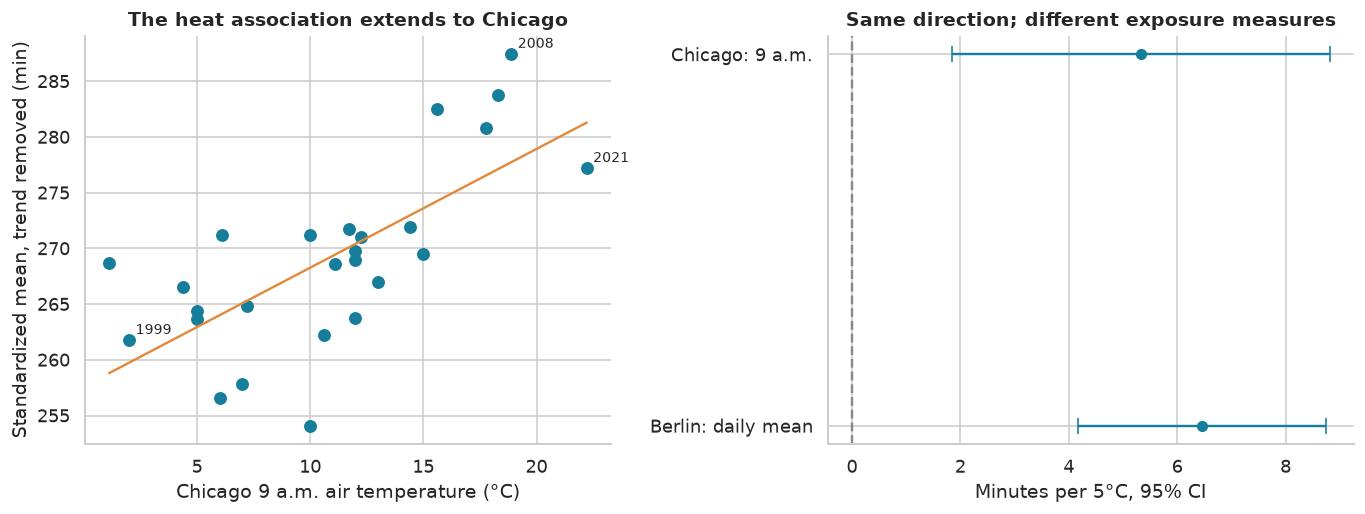

In [27]:
fig, axes = plt.subplots(1,2,figsize=(12,4.6))
chi_adjusted = chi_main.standardized_mean - chi_heat.params.year_c*chi_main.year_c
axes[0].scatter(chi_main.temp_c,chi_adjusted,s=50,color='#167d9a')
xx = np.linspace(chi_main.temp_c.min(),chi_main.temp_c.max(),100)
axes[0].plot(xx,chi_heat.params.Intercept+chi_heat.params.temp_c*xx,color='#e18a3b')
for year in [1999,2008,2021]:
    r=chi_main.loc[chi_main.Year.eq(year)].iloc[0]
    axes[0].annotate(str(year),(r.temp_c,r.standardized_mean-chi_heat.params.year_c*r.year_c),
                     xytext=(4,4),textcoords='offset points',fontsize=9)
axes[0].set(xlabel='Chicago 9 a.m. air temperature (°C)',ylabel='Standardized mean, trend removed (min)',
            title='The heat association extends to Chicago')
compare=pd.DataFrame([{'race':'Berlin: daily mean','estimate':5*weather_result['estimate'],
                       'ci_low':5*weather_result['ci_low'],'ci_high':5*weather_result['ci_high']},
                      {'race':'Chicago: 9 a.m.','estimate':chi_results.iloc[0].estimate,
                       'ci_low':chi_results.iloc[0].ci_low,'ci_high':chi_results.iloc[0].ci_high}])
axes[1].errorbar(compare.estimate,[0,1],xerr=[compare.estimate-compare.ci_low,compare.ci_high-compare.estimate],
                 fmt='o',capsize=5,color='#167d9a')
axes[1].set_yticks([0,1],compare.race)
axes[1].axvline(0,color='#888888',linestyle='--')
axes[1].set(xlabel='Minutes per 5°C, 95% CI',title='Same direction; different exposure measures')
fig.tight_layout()
efigure('11_chicago_replication')

The Berlin and Chicago estimates have different weather definitions and demographic reference populations.
Their agreement in direction is useful external evidence, but a formal pooled effect would require
harmonized weather exposures. Estimated RH and wind enter a small 26-year model; wide intervals are
inconclusive rather than evidence of zero effect. RH depends on temperature, so an unadjusted RH correlation
can be especially misleading. We report adjusted estimates and do not equate humidity with precipitation.

# 10 · How much do race fields differ after matching demographics?

The fall-marathon source contains over two million results from 96 named races, across 546 race-year
combinations. It excludes small races and seasons outside September–November. Some age values are exact;
others are class boundaries. We harmonize only to broad decade groups.

Retain ages 20–69, M/F categories, positive finish times, and race-years with **at least 10 finishes in
each of ten age-decade/sex cells**. Retain races with at least eight eligible years. These rules support
stable comparisons but select larger, recurrent races. Do not extrapolate to all marathons.

Standardize every race-year to the same pooled age/sex distribution. Then fit annual means against race
and year indicators, and predict each race with equal weight for all ten calendar years. Each race-year
has equal weight in this second-stage comparison. Rankings describe the **field plus event context**:
they cannot isolate hills, course speed, entry policies, weather, or training.
Chicago overlaps the standalone source and is not an additional independent weather replication here.

In [28]:
fall_raw = pd.read_csv(ROOT / 'data/raw/fall_marathons/Results.csv',
                       usecols=['Race','Year','Gender','Age','Finish'])
fall = fall_raw.loc[fall_raw.Age.between(20,69) & fall_raw.Gender.isin(['M','F']) & fall_raw.Finish.gt(0)].copy()
fall['age_decade'] = (fall.Age//10*10).astype(int)
fall['minutes'] = fall.Finish/60
fall_cells = fall.groupby(['Race','Year','age_decade','Gender']).minutes.agg(n='size',mean='mean').reset_index()
fall_coverage = fall_cells.groupby(['Race','Year']).agg(cells=('n','size'),minimum_cell_n=('n','min'))
eligible_events = fall_coverage.loc[(fall_coverage.cells==10)&(fall_coverage.minimum_cell_n>=10)].reset_index()
race_year_counts = eligible_events.groupby('Race').Year.nunique()
eligible_events = eligible_events.loc[eligible_events.Race.isin(race_year_counts[race_year_counts>=8].index)]
fall_analysis = fall.merge(eligible_events[['Race','Year']],on=['Race','Year'],validate='many_to_one')
fall_weights = fall_analysis.groupby(['age_decade','Gender']).size()/len(fall_analysis)
fall_means = fall_analysis.groupby(['Race','Year','age_decade','Gender']).minutes.mean().unstack(['age_decade','Gender'])
fall_means = fall_means.reindex(columns=fall_weights.index)
assert fall_means.notna().all().all() and np.isclose(fall_weights.sum(),1)
fall_annual = fall_means.mul(fall_weights,axis=1).sum(axis=1).rename('standardized_mean').reset_index()
fall_annual = fall_annual.merge(fall_analysis.groupby(['Race','Year']).minutes.agg(raw_mean='mean',n='size').reset_index(),
                              on=['Race','Year'],validate='one_to_one')
fall_model = smf.ols('standardized_mean ~ C(Race) + C(Year)',fall_annual).fit()
etable(fall_annual,'fall_race_years')
expansion_audit.append({'source':'Fall marathons','raw_rows':len(fall_raw),'eligible_rows':len(fall),
                        'analysis_rows':len(fall_analysis),'inference_unit_count':len(fall_annual),
                        'note':f'{fall_analysis.Race.nunique()} races, >=8 eligible years; overlaps Chicago.'})
print(f'Source: {len(fall_raw):,} rows, {fall_raw.Race.nunique()} races, {fall_raw.groupby(["Race","Year"]).ngroups} events.')
print(f'Analysis: {len(fall_analysis):,} rows, {fall_analysis.Race.nunique()} races, {len(fall_annual)} events.')

Source: 2,053,366 rows, 96 races, 546 events.
Analysis: 1,624,823 rows, 21 races, 199 events.


,race,n_years,n_finishes,raw_mean,adjusted_mean,annual_min,annual_max
0,Steamtown Marathon,10,17455,252.596,251.905,242.427,265.909
1,Indianapolis Monumental Marathon,9,34693,256.413,256.094,253.853,258.665
2,Wineglass Marathon,10,17005,261.291,256.608,245.656,265.959
3,Lakefront Marathon,10,20104,257.658,256.741,253.341,259.583
4,Hartford Marathon,10,20012,258.221,258.198,252.490,266.235
5,Grand Rapids Marathon,8,10049,260.606,259.896,254.426,267.843
6,Twin Cities Marathon,10,80484,259.621,260.378,256.810,264.597
7,Philadelphia Marathon,10,95607,258.999,260.486,255.494,263.540
8,St. George Marathon,10,50807,265.754,264.433,254.725,271.268
9,Columbus Marathon,10,42835,263.787,265.151,257.007,273.925


90th–10th percentile spread of race means: raw 38.2, adjusted 36.7 min.


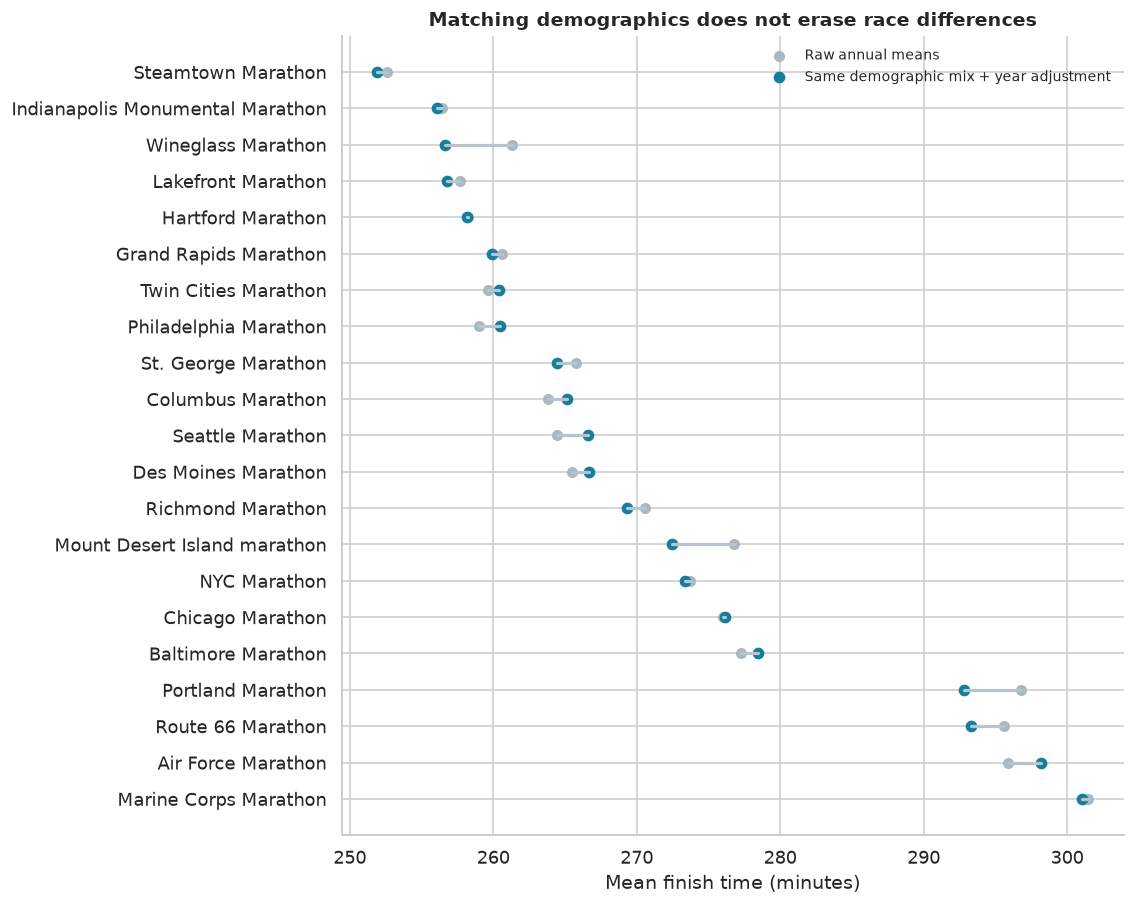

In [29]:
race_comparison = []
for race in sorted(fall_annual.Race.unique()):
    subset = fall_annual.loc[fall_annual.Race.eq(race)]
    adjusted = fall_model.predict(pd.DataFrame({'Race':race,'Year':range(2010,2020)})).mean()
    race_comparison.append({'race':race,'n_years':len(subset),'n_finishes':int(subset.n.sum()),
                            'raw_mean':subset.raw_mean.mean(),'adjusted_mean':adjusted,
                            'annual_min':subset.standardized_mean.min(),'annual_max':subset.standardized_mean.max()})
race_comparison = pd.DataFrame(race_comparison).sort_values('adjusted_mean').reset_index(drop=True)
race_spread = float(race_comparison.adjusted_mean.quantile(.9)-race_comparison.adjusted_mean.quantile(.1))
raw_race_spread = float(race_comparison.raw_mean.quantile(.9)-race_comparison.raw_mean.quantile(.1))
etable(race_comparison,'race_comparison')
display(race_comparison)
print(f'90th–10th percentile spread of race means: raw {raw_race_spread:.1f}, adjusted {race_spread:.1f} min.')
fig,ax=plt.subplots(figsize=(10,8))
for i,row in race_comparison.iterrows():
    ax.plot([row.raw_mean,row.adjusted_mean],[i,i],color='#b8c4cc',linewidth=2)
ax.scatter(race_comparison.raw_mean,race_comparison.index,color='#aab8c2',label='Raw annual means',s=35)
ax.scatter(race_comparison.adjusted_mean,race_comparison.index,color='#167d9a',label='Same demographic mix + year adjustment',s=40)
ax.set_yticks(race_comparison.index,race_comparison.race)
ax.invert_yaxis();ax.legend(frameon=False,fontsize=9)
ax.set(xlabel='Mean finish time (minutes)',title='Matching demographics does not erase race differences')
fig.tight_layout();efigure('12_race_comparison')

Race ordering is descriptive, not a league table of course difficulty. Runners self-select races, and
charity entrants, qualification policies, time limits, and geography can change the field.
A difference that remains after age/sex adjustment is an invitation to collect those variables,
not permission to call the remaining difference an elevation effect.

# 11 · Boston: where does performance break down?

Boston 2015–2017 includes intermediate checkpoints. Define **second-half slowdown** as
`100 × (second_half / first_half − 1)`: 10 means the second half took 10% longer.
Do not call this a diagnosis of “hitting the wall”; terrain, pacing, heat, injury, and stops can all contribute.

Checkpoint validation is specific to each analysis. A valid halfway comparison needs a half time and finish
with `0 < half < finish`. Segment profiles require all checkpoints to increase. A first-10-km prediction
needs `0 < 10K < finish`. We do not throw away an otherwise usable record because an unrelated split is missing.

In [30]:
boston_parts = []
for year in [2015,2016,2017]:
    part = pd.read_csv(ROOT / f'data/raw/boston_2015_2017/marathon_results_{year}.csv',low_memory=False)
    part['year'] = year
    for col in ['5K','10K','15K','20K','Half','25K','30K','35K','40K','Official Time']:
        part[col+'_min'] = pd.to_timedelta(part[col],errors='coerce').dt.total_seconds()/60
    part['sex'] = part['M/F']
    part['finish'] = part['Official Time_min']
    part['half'] = part['Half_min']
    part['second'] = part.finish-part.half
    boston_parts.append(part)
boston_all = pd.concat(boston_parts,ignore_index=True)
boston_valid = boston_all.loc[boston_all.half.gt(0) & boston_all.second.gt(0)
                             & boston_all.sex.isin(['M','F']) & boston_all.Age.between(18,90)].copy()
boston_valid['slow_pct'] = 100*(boston_valid.second/boston_valid.half-1)
pacing_summary = boston_valid.groupby(['year','sex']).agg(n=('slow_pct','size'),
    mean_slow_pct=('slow_pct','mean'),median_slow_pct=('slow_pct','median'),
    negative_split_pct=('slow_pct',lambda x:100*x.lt(0).mean()),
    large_slowdown_pct=('slow_pct',lambda x:100*x.ge(20).mean())).reset_index()
etable(pacing_summary,'boston_pacing_summary')
expansion_audit.append({'source':'Boston 2015–2017','raw_rows':len(boston_all),
                        'eligible_rows':len(boston_valid),'analysis_rows':len(boston_valid),
                        'inference_unit_count':3,'note':'Three event years; repeated participants possible.'})
display(pacing_summary)

,year,sex,n,mean_slow_pct,median_slow_pct,negative_split_pct,large_slowdown_pct
0,2015,F,11997,8.774,7.220,7.560,8.144
1,2015,M,14573,9.948,7.290,7.713,12.729
2,2016,F,12160,12.000,10.341,3.051,14.507
3,2016,M,14453,16.750,14.137,2.138,31.585
4,2017,F,11965,12.986,11.269,3.151,17.802
5,2017,M,14428,17.271,14.523,3.008,33.740


,question,estimate,ci_low,ci_high,p_value,year
0,"2015: male minus female slowdown, percentage p...",2.249,1.956,2.542,0.000,2015
1,"2016: male minus female slowdown, percentage p...",6.450,6.124,6.775,0.000,2016
2,"2017: male minus female slowdown, percentage p...",6.390,6.033,6.747,0.000,2017


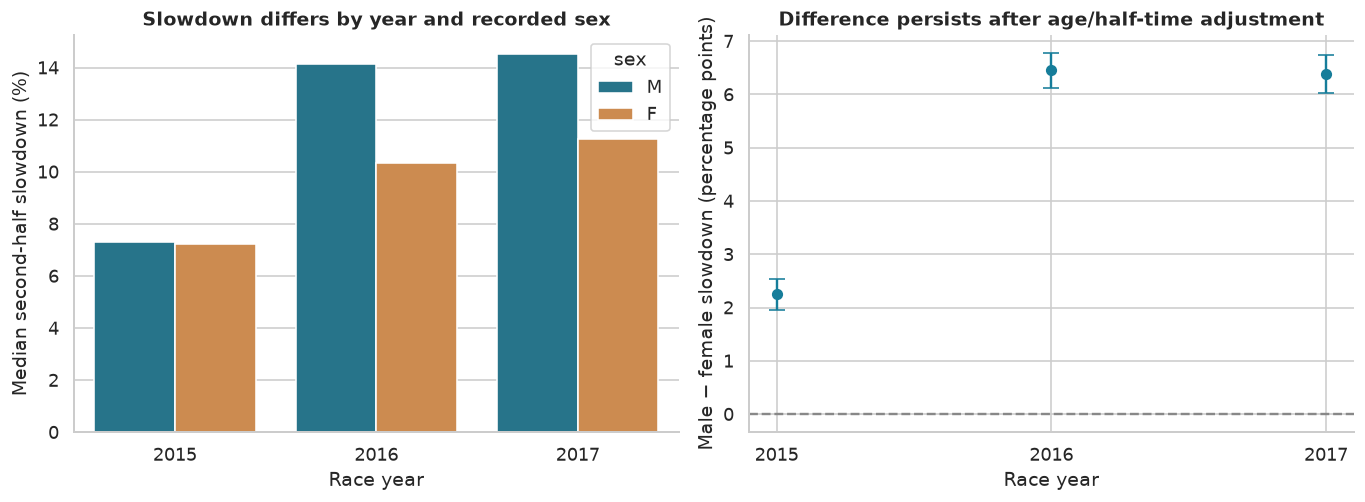

In [31]:
pace_adjustments = []
for year, data in boston_valid.groupby('year'):
    fit = smf.ols('slow_pct ~ C(sex) + bs(Age,df=4) + bs(half,df=5)',data).fit(cov_type='HC3',use_t=True)
    result = coefficient(fit,'C(sex)[T.M]',f'{year}: male minus female slowdown, percentage points')
    result['year'] = int(year)
    pace_adjustments.append(result)
pace_adjustments = etable(pd.DataFrame(pace_adjustments),'boston_adjusted_pacing')
display(pace_adjustments)
# Inference is conditional on each event. Do not pretend three weather days provide a heat test.
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
sns.barplot(data=pacing_summary,x='year',y='median_slow_pct',hue='sex',hue_order=['M','F'],ax=axes[0])
axes[0].set(xlabel='Race year',ylabel='Median second-half slowdown (%)',title='Slowdown differs by year and recorded sex')
axes[1].errorbar(pace_adjustments.year,pace_adjustments.estimate,
                 yerr=[pace_adjustments.estimate-pace_adjustments.ci_low,pace_adjustments.ci_high-pace_adjustments.estimate],
                 fmt='o',capsize=5,color='#167d9a')
axes[1].axhline(0,color='#888888',linestyle='--')
axes[1].set(xticks=[2015,2016,2017],xlabel='Race year',ylabel='Male − female slowdown (percentage points)',
            title='Difference persists after age/half-time adjustment')
fig.tight_layout();efigure('13_boston_pacing')

Adjusting for first-half time compares runners who reached halfway at similar times; it is not a
pre-race causal comparison. First-half time reflects ability, pacing decisions, and conditions and may
itself be affected by the variables under study. The age and half-time splines allow curved relationships.
Confidence intervals describe conditional within-year associations; they do not establish that the same
effect holds at all marathons or explain why it occurs.

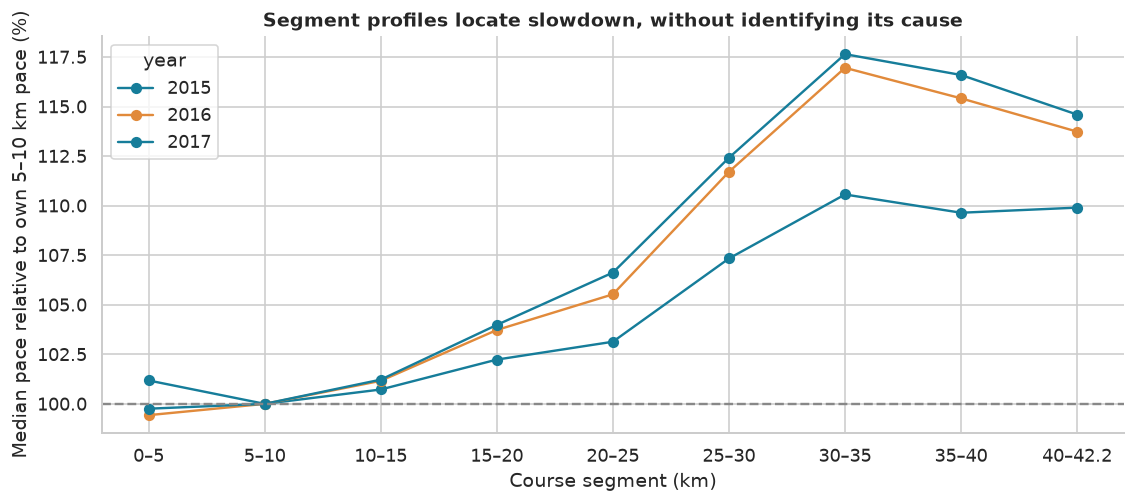

79,057 complete, increasing split profiles of 79,638 source records.


In [32]:
checkpoint_cols = [f'{k}K_min' for k in [5,10,15,20,25,30,35,40]]+['finish']
checkpoint_distances = np.array([5,10,15,20,25,30,35,40,42.195])
increments = boston_all[checkpoint_cols].diff(axis=1)
increments.iloc[:,0] = boston_all[checkpoint_cols[0]]
valid_profile = increments.notna().all(axis=1)&increments.gt(0).all(axis=1)
profile = increments.loc[valid_profile].div(np.diff(np.r_[0,checkpoint_distances]),axis=1)
# Divide by the 5–10 km pace, avoiding crowded opening-kilometer pace as the reference.
profile = profile.div(profile.iloc[:,1],axis=0)*100
profile['year'] = boston_all.loc[valid_profile,'year']
segment_profile = profile.groupby('year').median().T
segment_profile.index = ['0–5','5–10','10–15','15–20','20–25','25–30','30–35','35–40','40–42.2']
etable(segment_profile.reset_index(names='segment_km'),'boston_segment_profile')
fig,ax=plt.subplots(figsize=(10,4.5))
segment_profile.plot(marker='o',ax=ax)
ax.axhline(100,color='#888888',linestyle='--')
ax.set(xlabel='Course segment (km)',ylabel='Median pace relative to own 5–10 km pace (%)',
       title='Segment profiles locate slowdown, without identifying its cause')
fig.tight_layout();efigure('14_boston_segments')
print(f'{valid_profile.sum():,} complete, increasing split profiles of {len(boston_all):,} source records.')

## 11.1 · What can we predict after 10 km?

Prediction time matters. A race-day checkpoint is not a pre-race predictor. To avoid a tautological
advantage from predicting a total that already contains the observed split, the outcome is **time remaining
after 10 km**, not the whole finish. Compare a training-mean baseline, demographics, an extrapolation of
10-km pace, and a learned demographic-plus-10-km model.

Fit on 2015–2016, test on 2017. As a sensitivity check, evaluate only 2017 records whose normalized
name/sex/country/birth-year proxy does not appear in training. This screen reduces known repeat runners;
it cannot certify distinct people. No `Proj Time`, final rank, or later checkpoint enters the models.

In [33]:
from sklearn.preprocessing import SplineTransformer
# Conservative linkage proxy, used only for split checks/history—not exported as personal data.
def runner_key(frame):
    name = frame.Name.fillna('').str.normalize('NFKC').str.upper().str.replace(r'\s+',' ',regex=True).str.strip()
    return name+'|'+frame.sex+'|'+frame.Country.fillna('')+'|'+(frame.year-frame.Age).astype(str)

boston_all['runner_key'] = runner_key(boston_all)
checkpoint = boston_all.loc[boston_all['10K_min'].gt(0)&boston_all.finish.gt(boston_all['10K_min'])
                           & boston_all.sex.isin(['M','F']) & boston_all.Age.between(18,90)].copy()
checkpoint['remaining'] = checkpoint.finish-checkpoint['10K_min']
checkpoint_train = checkpoint.loc[checkpoint.year.lt(2017)]
checkpoint_test = checkpoint.loc[checkpoint.year.eq(2017)]
new_proxy_mask = ~checkpoint_test.runner_key.isin(set(checkpoint_train.runner_key))

def smooth_regression(categorical, numeric):
    preprocessor = ColumnTransformer([
        ('category',OneHotEncoder(drop='first',handle_unknown='ignore'),categorical),
        ('numeric',SplineTransformer(n_knots=5,degree=3,include_bias=False,extrapolation='linear'),numeric)
    ])
    return make_pipeline(preprocessor,LinearRegression())

checkpoint_predictions = {
    'Training remaining-time mean':np.repeat(checkpoint_train.remaining.mean(),len(checkpoint_test)),
    'Constant 10-km pace':checkpoint_test['10K_min'].to_numpy()*(42.195-10)/10
}
for name,numeric in [('Demographics',['Age']),('Demographics + first 10 km',['Age','10K_min'])]:
    model = smooth_regression(['sex'],numeric)
    model.fit(checkpoint_train[['sex']+numeric],checkpoint_train.remaining)
    checkpoint_predictions[name] = model.predict(checkpoint_test[['sex']+numeric])
checkpoint_metrics = []
for sample,mask in [('All eligible 2017',np.ones(len(checkpoint_test),dtype=bool)),
                    ('No training identity-proxy match',new_proxy_mask.to_numpy())]:
    target = checkpoint_test.remaining.to_numpy()[mask]
    for name,prediction in checkpoint_predictions.items():
        checkpoint_metrics.append({'sample':sample,'model':name,'n':int(mask.sum()),
                                   'mae':mean_absolute_error(target,prediction[mask]),
                                   'rmse':np.sqrt(mean_squared_error(target,prediction[mask])),
                                   'r2':r2_score(target,prediction[mask])})
checkpoint_metrics=etable(pd.DataFrame(checkpoint_metrics),'checkpoint_prediction')
display(checkpoint_metrics)

,sample,model,n,mae,rmse,r2
0,All eligible 2017,Training remaining-time mean,26356,27.135,35.727,-0.038
1,All eligible 2017,Constant 10-km pace,26356,22.266,28.687,0.331
2,All eligible 2017,Demographics,26356,24.312,33.102,0.109
3,All eligible 2017,Demographics + first 10 km,26356,13.000,18.609,0.718
4,No training identity-proxy match,Training remaining-time mean,19891,27.269,35.988,-0.055
5,No training identity-proxy match,Constant 10-km pace,19891,22.961,29.358,0.298
6,No training identity-proxy match,Demographics,19891,24.458,33.614,0.080
7,No training identity-proxy match,Demographics + first 10 km,19891,13.344,19.092,0.703


# 12 · Is a previous marathon more informative than demographic averages?

Names are not unique IDs. We cautiously link only exact normalized name, recorded sex, country,
and `year − age` matches across adjacent years; ambiguous keys within either year are excluded.
This strict rule misses legitimate matches when birthdays or recorded fields change and can still
falsely link different people. The analysis is restricted to the matched repeat-finisher subset.
A sensitivity subset additionally requires the same city and state.

Train on **2015 → 2016** pairs and test on **2016 → 2017** pairs. Prior race time is available before
the target race. Some people can occur in both transitions: this is legitimate future prediction for
known runners, not a claim of evaluating entirely unseen people. Compare a demographic spline model,
simply repeating the previous time, and a calibrated demographic-plus-prior-time model.
Do not interpret previous finish time as a direct measurement of training volume or experience.

In [34]:
def adjacent_pairs(first_year):
    candidates=boston_all.loc[boston_all.finish.gt(0)&boston_all.Age.between(18,90)
                              & boston_all.sex.isin(['M','F']) & boston_all.Name.notna()
                              & boston_all.Country.notna()].copy()
    left=candidates.loc[candidates.year.eq(first_year)]
    right=candidates.loc[candidates.year.eq(first_year+1)]
    left=left.loc[~left.duplicated('runner_key',keep=False)]
    right=right.loc[~right.duplicated('runner_key',keep=False)]
    return left.merge(right,on='runner_key',suffixes=('_prior','_next'),validate='one_to_one')

history_train,history_test = adjacent_pairs(2015),adjacent_pairs(2016)
history_predictions = {'Repeat previous finish':history_test.finish_prior.to_numpy()}
for name,numeric in [('Demographics',['Age_next']),('Demographics + previous finish',['Age_next','finish_prior'])]:
    model=smooth_regression(['sex_next'],numeric)
    model.fit(history_train[['sex_next']+numeric],history_train.finish_next)
    history_predictions[name]=model.predict(history_test[['sex_next']+numeric])
same_location = np.ones(len(history_test),dtype=bool)
for col in ['City','State']:
    same_location &= (history_test[col+'_prior'].fillna('').str.upper().str.strip()
                      ==history_test[col+'_next'].fillna('').str.upper().str.strip()).to_numpy()
history_metrics=[]
for sample,mask in [('All strict matches',np.ones(len(history_test),dtype=bool)),
                    ('Also same city/state',same_location)]:
    target=history_test.finish_next.to_numpy()[mask]
    for name,prediction in history_predictions.items():
        history_metrics.append({'sample':sample,'model':name,'n':int(mask.sum()),
            'mae':mean_absolute_error(target,prediction[mask]),'r2':r2_score(target,prediction[mask])})
history_metrics=etable(pd.DataFrame(history_metrics),'history_prediction')
display(history_metrics)
print(f'{len(history_train):,} training transitions and {len(history_test):,} held-out transitions.')
# Paired bootstrap over held-out matched runners; conditional on this one test event.
gain = (np.abs(history_test.finish_next.to_numpy()-history_predictions['Demographics'])
        -np.abs(history_test.finish_next.to_numpy()-history_predictions['Repeat previous finish']))
rng=np.random.default_rng(SEED)
bootstrap_gain=np.array([rng.choice(gain,len(gain),replace=True).mean() for _ in range(2000)])
history_gain_ci=np.quantile(bootstrap_gain,[.025,.975])
print(f'Previous-time baseline reduces MAE by {gain.mean():.2f} min; paired bootstrap 95% CI '
      f'{history_gain_ci[0]:.2f}–{history_gain_ci[1]:.2f}. This CI does not generalize across race years.')

,sample,model,n,mae,r2
0,All strict matches,Repeat previous finish,4922,15.143,0.709
1,All strict matches,Demographics,4922,27.841,0.195
2,All strict matches,Demographics + previous finish,4922,15.759,0.734
3,Also same city/state,Repeat previous finish,4400,15.157,0.703
4,Also same city/state,Demographics,4400,27.672,0.196
5,Also same city/state,Demographics + previous finish,4400,15.709,0.731


5,516 training transitions and 4,922 held-out transitions.
Previous-time baseline reduces MAE by 12.70 min; paired bootstrap 95% CI 12.00–13.42. This CI does not generalize across race years.


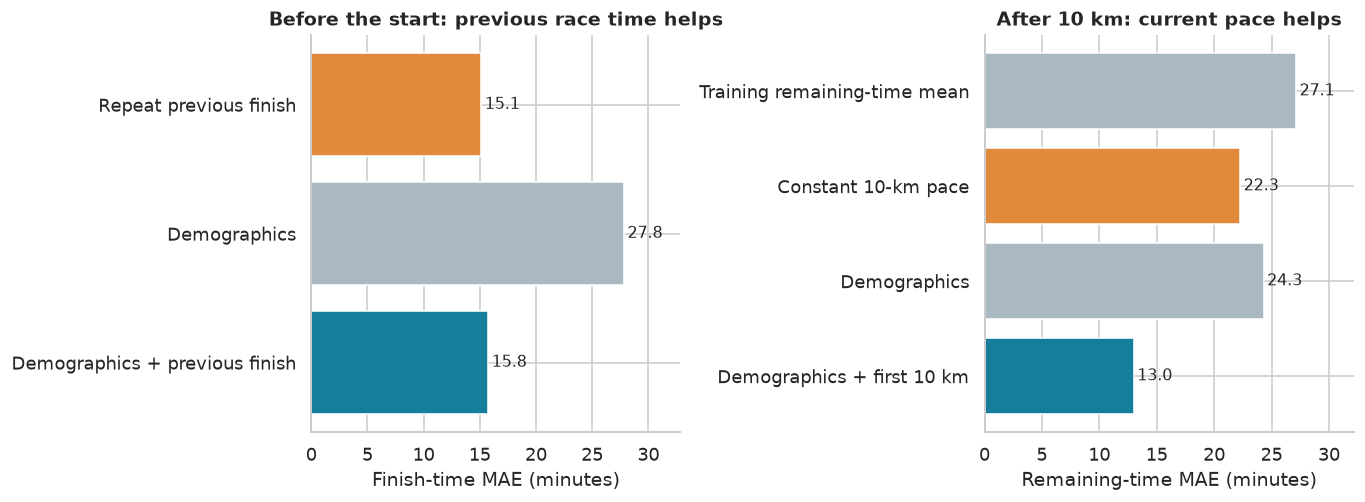

In [35]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
hs=history_metrics.loc[history_metrics['sample'].eq('All strict matches')]
cs=checkpoint_metrics.loc[checkpoint_metrics['sample'].eq('All eligible 2017')]
axes[0].barh(hs.model,hs.mae,color=['#e18a3b','#aab8c2','#167d9a'])
axes[0].invert_yaxis();axes[0].set(xlabel='Finish-time MAE (minutes)',title='Before the start: previous race time helps')
axes[1].barh(cs.model,cs.mae,color=['#aab8c2','#e18a3b','#aab8c2','#167d9a'])
axes[1].invert_yaxis();axes[1].set(xlabel='Remaining-time MAE (minutes)',title='After 10 km: current pace helps')
for ax,values in [(axes[0],hs.mae),(axes[1],cs.mae)]:
    for i,value in enumerate(values):ax.text(value+.3,i,f'{value:.1f}',va='center',fontsize=10)
    ax.set_xlim(0,max(values)+5)
fig.tight_layout();efigure('15_information_prediction')

These panels have different populations and different prediction times; their errors must not be
compared as if they were one model competition. Within each panel the models share exactly the same
test rows. History predicts a complete future finish; the checkpoint model predicts only what remains
after 10 km. The simpler previous-finish baseline is retained even if it outperforms the calibrated model.

# 13 · Does recent home weather predict less slowdown in Boston 2024?

This directly addresses the classmate's acclimatization question, but only through a proxy.
The source contains U.S. runners with ZIP codes and daily home-area temperatures. Home weather does not
establish where, when, or whether someone trained outdoors. Travel, indoor training, and acclimatization
remain unobserved.

**Join audit:** preserve ZIP codes as five-character strings, padding lost leading zeros in both files.
The weather file contains April 1–15. Exclude **April 15 (race day)**, leaving 14 strictly preceding days.
Require complete daily coverage for a ZIP; use a many-to-one join and report unmatched runners.
This avoids mixing race-day weather into the stated pre-race window. We also exclude all 22 records
belonging to 11 duplicated bib numbers with conflicting split/finish values; the correct record cannot
be identified from this source. A sensitivity check includes them without choosing a preferred value.

Outcome: percentage second-half slowdown. Primary exploratory model: home mean temperature, age spline,
recorded sex, and first-half-time spline. A 5°C increase is the reporting unit. Use standard errors
clustered by the **first three ZIP digits** to acknowledge shared regional weather. This is a partial
spatial adjustment, not a perfect geographic independence assumption. Models without half-time adjustment,
ZIP-level clustering, and minimum-temperature exposure are sensitivity checks.

In [36]:
home_athletes=pd.read_csv(ROOT/'data/raw/boston_2024/Athletes.csv',dtype={'Zip':'string'})
home_weather=pd.read_csv(ROOT/'data/raw/boston_2024/Weather.csv',dtype={'Zip':'string'})
raw_zip_matches=home_athletes.Zip.isin(set(home_weather.Zip)).sum()
for frame in [home_athletes,home_weather]:
    frame['Zip']=frame.Zip.str.strip().str.zfill(5)
    assert frame.Zip.str.fullmatch(r'\d{5}').all()
home_weather['date']=pd.to_datetime(home_weather.Date,format='%m/%d/%y')
assert not home_weather.duplicated(['Zip','date']).any()
pre_weather=home_weather.loc[home_weather.date.between('2024-04-01','2024-04-14')]
home_exposure=pre_weather.groupby('Zip').agg(days=('date','nunique'),home_f=('Mean Temp','mean'),
                                           home_min_f=('Min Temp','mean'),home_max_f=('Max Temp','mean')).reset_index()
home_exposure=home_exposure.loc[home_exposure.days.eq(14)]
home_joined=home_athletes.merge(home_exposure,on='Zip',how='left',validate='many_to_one',indicator=True)
home_unmatched=int(home_joined['_merge'].ne('both').sum())
home_ambiguous_bibs = home_athletes.loc[home_athletes.Bib.duplicated(keep=False),'Bib'].unique()
home_ambiguous_rows = int(home_athletes.Bib.isin(home_ambiguous_bibs).sum())
assert (home_athletes['First Half']+home_athletes['Second Half']).eq(home_athletes.Finish).all()
home_with_conflicts=home_joined.loc[home_joined['_merge'].eq('both') & home_joined['First Half'].gt(0)
                     & home_joined['Second Half'].gt(0) & home_joined.Gender.isin(['M','F'])
                     & home_joined.Age.between(18,90)].copy()
home = home_with_conflicts.loc[~home_with_conflicts.Bib.isin(home_ambiguous_bibs)].copy()
assert home.Bib.is_unique
home['home_c']=(home.home_f-32)/1.8
home['home5']=home.home_c/5
home['home_min5']=(home.home_min_f-32)/9
home['half_min']=home['First Half']/60
home['slow_pct']=100*(home['Second Half']/home['First Half']-1)
home['zip3']=home.Zip.str[:3]
assert np.allclose(home.slow_pct/100,home['Percent Change'])
expansion_audit.append({'source':'Boston 2024','raw_rows':len(home_athletes),'eligible_rows':len(home),
                        'analysis_rows':len(home),'inference_unit_count':home.zip3.nunique(),
                        'note':f'{home_unmatched} unmatched ZIPs; {home_ambiguous_rows} conflicting-bib rows excluded; one event.'})
print(f'Before ZIP normalization: {raw_zip_matches:,} matching records. After normalization: '
      f'{len(home_with_conflicts):,}; unmatched: {home_unmatched}; then exclude {home_ambiguous_rows} conflicting-bib rows.')
print(f'{home.Zip.nunique():,} home ZIPs; {home.zip3.nunique()} ZIP-prefix clusters; 14 days per matched ZIP.')

Before ZIP normalization: 11,857 matching records. After normalization: 17,191; unmatched: 29; then exclude 22 conflicting-bib rows.
5,878 home ZIPs; 751 ZIP-prefix clusters; 14 days per matched ZIP.


,question,estimate,ci_low,ci_high,p_value
0,Unadjusted,-0.178,-0.536,0.179,0.329
1,Age and sex only,-0.263,-0.639,0.113,0.171
2,"Age, sex, first-half time",0.163,-0.144,0.470,0.298
3,Cluster by individual ZIP,0.163,-0.086,0.412,0.199
4,Mean daily minimum temperature,0.176,-0.138,0.490,0.272
5,Include conflicting bib records,0.163,-0.144,0.470,0.298


,temp_bin,n,home_mean_c,mean_slow_pct,median_slow_pct
0,"[-10, 0)",72,-1.741,15.717,12.453
1,"[0, 5)",224,3.795,15.493,11.294
2,"[5, 10)",9888,7.749,16.168,13.877
3,"[10, 15)",4461,12.317,15.536,12.694
4,"[15, 20)",1521,17.035,15.995,13.233
5,"[20, 25)",1003,21.373,16.233,13.305


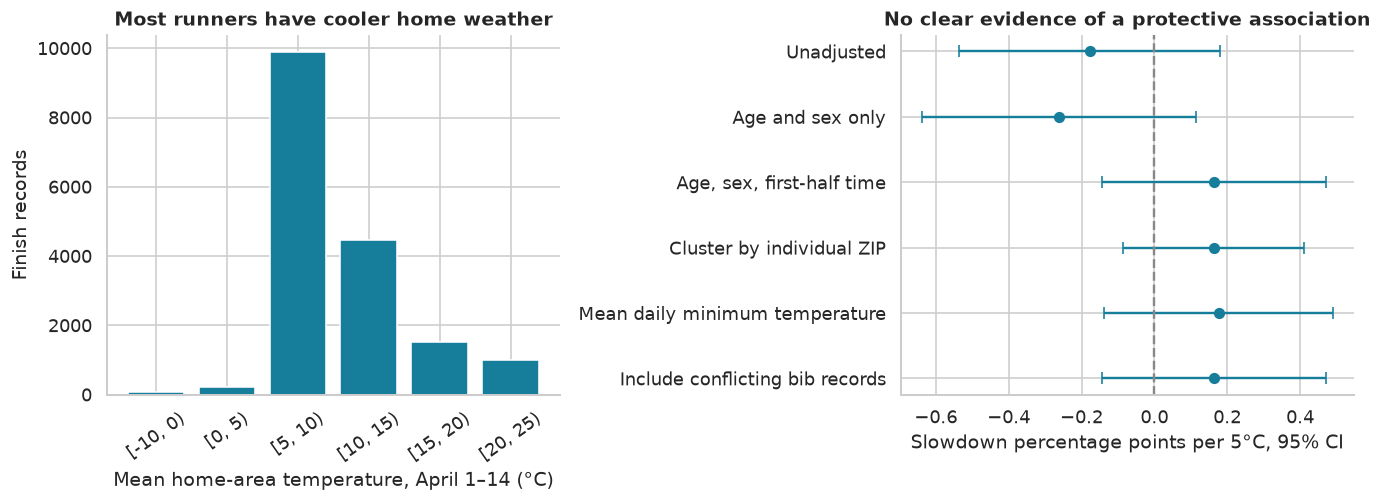

In [37]:
home_formula='slow_pct ~ home5 + bs(Age,df=4) + C(Gender) + bs(half_min,df=5)'
home_fit=smf.ols(home_formula,home).fit(cov_type='cluster',cov_kwds={'groups':home.zip3},use_t=True)
home_result=coefficient(home_fit,'home5','Home temperature: slowdown points per 5°C')
home_sensitivity=[]
for name,formula,group,term in [
    ('Unadjusted','slow_pct ~ home5','zip3','home5'),
    ('Age and sex only','slow_pct ~ home5 + bs(Age,df=4) + C(Gender)','zip3','home5'),
    ('Age, sex, first-half time',home_formula,'zip3','home5'),
    ('Cluster by individual ZIP',home_formula,'Zip','home5'),
    ('Mean daily minimum temperature',home_formula.replace('home5','home_min5'),'zip3','home_min5')
]:
    fit=smf.ols(formula,home).fit(cov_type='cluster',cov_kwds={'groups':home[group]},use_t=True)
    home_sensitivity.append(coefficient(fit,term,name))
# Include ambiguous bib rows as a sensitivity check, never select one arbitrarily.
hc = home_with_conflicts.copy()
hc['home5']=(hc.home_f-32)/9
hc['half_min']=hc['First Half']/60
hc['slow_pct']=100*(hc['Second Half']/hc['First Half']-1)
hc['zip3']=hc.Zip.str[:3]
hc_fit=smf.ols(home_formula,hc).fit(cov_type='cluster',cov_kwds={'groups':hc.zip3},use_t=True)
home_sensitivity.append(coefficient(hc_fit,'home5','Include conflicting bib records'))
home_sensitivity=etable(pd.DataFrame(home_sensitivity),'home_weather_sensitivity')
display(home_sensitivity)
# Grouped descriptions display the actual support, not a fitted causal response.
home['temp_bin']=pd.cut(home.home_c,[-10,0,5,10,15,20,25,35],right=False)
home_bins=home.groupby('temp_bin',observed=True).agg(n=('slow_pct','size'),home_mean_c=('home_c','mean'),
                                                  mean_slow_pct=('slow_pct','mean'),median_slow_pct=('slow_pct','median')).reset_index()
etable(home_bins,'home_weather_bins')
display(home_bins)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar(home_bins.temp_bin.astype(str),home_bins.n,color='#167d9a')
axes[0].tick_params(axis='x',rotation=35)
axes[0].set(xlabel='Mean home-area temperature, April 1–14 (°C)',ylabel='Finish records',title='Most runners have cooler home weather')
axes[1].errorbar(home_sensitivity.estimate,np.arange(len(home_sensitivity)),
                 xerr=[home_sensitivity.estimate-home_sensitivity.ci_low,home_sensitivity.ci_high-home_sensitivity.estimate],
                 fmt='o',capsize=4,color='#167d9a')
axes[1].set_yticks(range(len(home_sensitivity)),home_sensitivity.question)
axes[1].axvline(0,color='#888888',linestyle='--');axes[1].invert_yaxis()
axes[1].set(xlabel='Slowdown percentage points per 5°C, 95% CI',title='No clear evidence of a protective association')
fig.tight_layout();efigure('16_home_weather')

A null or specification-sensitive home-weather association does not disprove heat acclimatization.
This proxy does not measure training exposure, the study includes only one race, and conditioning on
first-half time changes the comparison. We can answer whether this measured proxy predicts the recorded
slowdown, not whether acclimatization is physiologically effective.

# 14 · What additional data did not earn a scientific claim?

We inspected nine expansion candidates. NYC overlaps the fall sample and adds no weather in its current
description; the 2024 all-marathon source adds recency but not the missing training exposure.
The Run Club dataset explicitly states that it is **synthetic**, so it is excluded from real-world claims.

The 87-row training pilot is real-world but not suitable for the proposed pre-race prediction:
the uploader says mileage includes the marathon, one speed is implausibly large, cross-training is
mostly missing, and finish-derived categories would leak the outcome. We do not silently repair units
or treat those data as reliable training history. This records a limitation of the sources searched,
not a claim that no suitable training dataset exists anywhere.

In [38]:
pilot=pd.read_csv(ROOT/'data/raw/training_pilot/MarathonData.csv')
pilot_audit=pd.DataFrame([
    {'check':'Rows','value':len(pilot)},
    {'check':'Missing cross-training entries','value':int(pilot.CrossTraining.isna().sum())},
    {'check':'Missing demographic category','value':int(pilot.Category.isna().sum())},
    {'check':'Speed entries above 40 (declared speed context)','value':int(pilot.sp4week.gt(40).sum())},
    {'check':'Maximum recorded speed field','value':float(pilot.sp4week.max())}
])
etable(pilot_audit,'training_pilot_audit');display(pilot_audit)
# This audit excludes names and other direct runner identifiers from exported results.
audit_table=etable(pd.DataFrame(expansion_audit),'expansion_cleaning_audit')
display(audit_table)
# Four focal exploratory tests; sensitivities are not new independent confirmations.
focal=pd.DataFrame([chi_results.iloc[0].to_dict(),chi_results.iloc[2].to_dict(),
                    chi_results.iloc[3].to_dict(),home_result])
focal['q_bh']=multipletests(focal.p_value,method='fdr_bh')[1]
etable(focal,'expansion_focal_tests');display(focal)

,check,value
0,Rows,87.000
1,Missing cross-training entries,74.000
2,Missing demographic category,6.000
3,Speed entries above 40 (declared speed context),1.000
4,Maximum recorded speed field,"11,125.000"


,source,raw_rows,eligible_rows,analysis_rows,inference_unit_count,note
0,Chicago,886546,877341,852085,26,Ages 20–69; main weather fit excludes interrup...
1,Fall marathons,2053366,1990309,1624823,199,"21 races, >=8 eligible years; overlaps Chicago."
2,Boston 2015–2017,79638,79576,79576,3,Three event years; repeated participants possi...
3,Boston 2024,17220,17169,17169,751,29 unmatched ZIPs; 22 conflicting-bib rows exc...


,question,estimate,ci_low,ci_high,p_value,q_bh
0,"Chicago: temperature, minutes per 5°C",5.328,1.843,8.812,0.004,0.017
1,"Chicago: RH, minutes per 10 percentage points",-0.827,-4.327,2.672,0.628,0.837
2,"Chicago: wind, minutes per 5 source units",-0.300,-4.251,3.652,0.876,0.876
3,Home temperature: slowdown points per 5°C,0.163,-0.144,0.470,0.298,0.596


## Integrated interpretation and remaining work

**Weather:** Chicago checks whether the Berlin heat association survives a different event. Humidity
is now estimated from temperature and dew point; wind is observed, but the small annual sample and
weather correlation limit the precision of separate effects. Do not call wide intervals evidence of no effect.

**Race context:** demographic adjustment leaves substantial differences across fields. Course difficulty
remains a possible explanation, alongside runner selection and unmeasured conditions; it is not identified.

**Pacing and prediction:** Boston supplies observable within-race slowdown and prior-race history.
Predictive comparisons must preserve when information becomes available and use the same test population.
Repeated-race history is informative without being a measure of training frequency.

**Acclimatization:** recent home weather can be examined as a proxy; actual training exposure cannot.
A clean join, a truly pre-race window, spatial clustering, and sensitivity checks are essential.

This remains observational analysis. No new dataset erases the need to handle selection, dependence,
measurement definitions, source overlap, and missing variables. All focal extension tests are exploratory;
BH-adjusted q-values are reported for the four focal weather/home-weather tests. Race rankings and
checkpoint/model comparisons are descriptive, not additional significance tests.

In [39]:
expanded_summary={
    'sources':source_catalog.to_dict(orient='records'),
    'audit':audit_table.to_dict(orient='records'),
    'chicago_results':chi_results.to_dict(orient='records'),
    'chicago_sensitivity':chi_sens.to_dict(orient='records'),
    'chicago_loo_min':float(chi_loo.slope_per_5c.min()),'chicago_loo_max':float(chi_loo.slope_per_5c.max()),
    'race_count':int(fall_analysis.Race.nunique()),'race_event_count':len(fall_annual),
    'race_raw_spread':raw_race_spread,'race_adjusted_spread':race_spread,
    'race_comparison':race_comparison.to_dict(orient='records'),
    'pacing_summary':pacing_summary.to_dict(orient='records'),
    'pacing_adjusted':pace_adjustments.to_dict(orient='records'),
    'checkpoint_metrics':checkpoint_metrics.to_dict(orient='records'),
    'history_metrics':history_metrics.to_dict(orient='records'),
    'history_train_n':len(history_train),'history_test_n':len(history_test),
    'history_mae_gain':float(gain.mean()),'history_gain_ci':history_gain_ci.tolist(),
    'home_result':home_result,'home_sensitivity':home_sensitivity.to_dict(orient='records'),
    'home_n':len(home),'home_zip_count':int(home.Zip.nunique()),'home_cluster_count':int(home.zip3.nunique()),
    'home_unmatched':home_unmatched,'home_ambiguous_rows':home_ambiguous_rows,
    'home_normalized_matches':len(home_with_conflicts),'home_raw_zip_matches':int(raw_zip_matches),
    'focal_tests':focal.to_dict(orient='records'),'pilot_audit':pilot_audit.to_dict(orient='records')
}
history_display = history_metrics.loc[history_metrics['sample'].eq('All strict matches')].set_index('model')
checkpoint_display = checkpoint_metrics.loc[checkpoint_metrics['sample'].eq('All eligible 2017')].set_index('model')
display(Markdown(f"""
### Expanded results in plain language

- **Chicago replication:** {chi_results.iloc[0].estimate:.1f} extra minutes per 5°C
  (95% CI {chi_results.iloc[0].ci_low:.1f}–{chi_results.iloc[0].ci_high:.1f}) in the standardized annual mean.
- **Humidity and wind:** estimated separately in Chicago, but intervals include zero and remain wide.
- **Race context:** a {race_spread:.1f}-minute 90th–10th percentile spread remains between adjusted means
  across {fall_analysis.Race.nunique()} supported race fields; this is not an elevation effect estimate.
- **Prior history:** held-out MAE is {history_display.loc['Demographics','mae']:.1f} minutes for demographics
  versus {history_display.loc['Repeat previous finish','mae']:.1f} for the previous-time baseline among matched repeaters.
- **After 10 km:** remaining-time MAE falls from {checkpoint_display.loc['Demographics','mae']:.1f}
  to {checkpoint_display.loc['Demographics + first 10 km','mae']:.1f} minutes when observed pace is available.
- **Home weather:** {home_result['estimate']:.2f} slowdown points per 5°C
  (95% CI {home_result['ci_low']:.2f}–{home_result['ci_high']:.2f}); no clear protective association from this proxy.
"""))
(EXP/'results.json').write_text(json.dumps(expanded_summary,indent=2,default=float)+'\n')
print('Saved the expanded evidence bundle; Chapter 15 adds training and renders the integrated report.')


### Expanded results in plain language

- **Chicago replication:** 5.3 extra minutes per 5°C
  (95% CI 1.8–8.8) in the standardized annual mean.
- **Humidity and wind:** estimated separately in Chicago, but intervals include zero and remain wide.
- **Race context:** a 36.7-minute 90th–10th percentile spread remains between adjusted means
  across 21 supported race fields; this is not an elevation effect estimate.
- **Prior history:** held-out MAE is 27.8 minutes for demographics
  versus 15.1 for the previous-time baseline among matched repeaters.
- **After 10 km:** remaining-time MAE falls from 24.3
  to 13.0 minutes when observed pace is available.
- **Home weather:** 0.16 slowdown points per 5°C
  (95% CI -0.14–0.47); no clear protective association from this proxy.


Saved the expanded evidence bundle; Chapter 15 adds training and renders the integrated report.


# 15 · Actual training logs: volume, frequency, and a carefully labeled outcome

A further search found a sixth substantive Kaggle dataset:
[Long-distance running dataset, v1](https://www.kaggle.com/datasets/mexwell/long-distance-running-dataset),
a mirror of [Afonseca, Watanabe & Duarte's open research data](https://pmc.ncbi.nlm.nih.gov/articles/PMC8958962/).
Unlike the 87-row pilot, this source contains anonymous athlete IDs and daily running totals.
We download only the 2019 daily file. It contains **13,290,380 athlete-day rows**, including zero-activity
days, for 36,412 athletes. These rows are not 13 million independent runs or race finishes.
Age groups are coarse and were estimated by the original researchers; they are not exact ages.

We select athletes labeled as Boston 2019 or Chicago 2019 participants and extract the 56 days before
each event. Boston's date is [April 15, 2019, verified by the BAA](https://www.baa.org/news/baa-announces-2019-boston-marathon-registration-dates/);
Chicago's October 13 date is in the downloaded Chicago weather file. **Race day is never part of a training feature.**

The outcome needs care: the logs do not contain certified finish times. We use **logged race-day running
duration**, restricting the day's distance to 40–46 km and duration to 120–480 minutes. Daily totals can
include warm-up, cool-down, pauses or recording artifacts. This is a marathon-day proxy, not official
finishing time. We do not normalize duration by GPS distance, because measurement error may inflate distance.

Require all 56 day rows and positive total pre-race mileage. Flag a training window if any day has negative
or missing distance/duration, inconsistent zero distance/time, or positive-distance pace outside 2–20 min/km.
Exclude flagged windows rather than silently repair them. These are consistency rules, not proof every
excluded activity is wrong. Zero logs are absence of recorded running, not proof of no exercise.

In [40]:
training_dir=ROOT/'data/raw/training_logs'
training_manifest=json.loads((training_dir/'manifest.json').read_text())
for filename,expected in training_manifest['files'].items():
    with (training_dir/filename).open('rb') as handle:
        assert hashlib.file_digest(handle,'sha256').hexdigest()==expected
race_dates={'BOSTON 2019':'2019-04-15','CHICAGO 2019':'2019-10-13'}
selected_windows=[]
training_raw_rows=0
training_athletes=set()
# Stream a 956 MB source rather than load all 13 million rows into memory.
cols=['datetime','athlete','distance','duration','gender','age_group','major']
for chunk in pd.read_csv(training_dir/'run_ww_2019_d.csv',usecols=cols,chunksize=250000):
    training_raw_rows+=len(chunk)
    training_athletes.update(chunk.athlete.unique())
    for race,date in race_dates.items():
        start=str((pd.Timestamp(date)-pd.Timedelta(days=56)).date())
        keep=chunk.major.str.contains(race,regex=False,na=False)&chunk.datetime.between(start,date)
        selected=chunk.loc[keep].copy()
        selected['race']=race
        selected['race_date']=date
        selected_windows.append(selected)
logs=pd.concat(selected_windows,ignore_index=True)
del selected_windows,chunk
logs['date']=pd.to_datetime(logs.datetime)
logs['race_date']=pd.to_datetime(logs.race_date)
assert not logs.duplicated(['athlete','race','date']).any()
pre_logs=logs.loc[logs.date.lt(logs.race_date)].copy()
race_logs=logs.loc[logs.date.eq(logs.race_date)].copy()
pre_logs['daily_pace']=pre_logs.duration/pre_logs.distance
pre_logs['flagged']=(pre_logs.distance.isna()|pre_logs.duration.isna()|pre_logs.distance.lt(0)|pre_logs.duration.lt(0)
    |(pre_logs.distance.eq(0)^pre_logs.duration.eq(0))
    |(pre_logs.distance.gt(0)&~pre_logs.daily_pace.between(2,20)))
pre_logs['week_before']=((pre_logs.race_date-pre_logs.date).dt.days-1)//7+1
pre_logs['active']=pre_logs.distance.gt(0)
print(f'{training_raw_rows:,} daily rows; {len(training_athletes):,} athletes; {len(logs):,} relevant window/day rows.')
print(f'{pre_logs.flagged.sum()} flagged training days in '
      f'{pre_logs.loc[pre_logs.flagged].groupby(["athlete","race"]).ngroups} athlete/race windows.')

13,290,380 daily rows; 36,412 athletes; 320,226 relevant window/day rows.
201 flagged training days in 139 athlete/race windows.


In [41]:
training_windows=pre_logs.groupby(['athlete','race']).agg(
    observed_days=('date','nunique'),km=('distance','sum'),training_minutes=('duration','sum'),
    active_days=('active','sum'),flagged_days=('flagged','sum'),
    latest_training_date=('date','max')).reset_index()
active_weeks=pre_logs.loc[pre_logs.active].groupby(['athlete','race']).week_before.nunique().rename('active_weeks')
training_windows=training_windows.merge(active_weeks,on=['athlete','race'],how='left',validate='one_to_one')
training_windows=training_windows.merge(race_logs[['athlete','race','distance','duration','gender','age_group','race_date']],
                                       on=['athlete','race'],validate='one_to_one')
valid_training=(training_windows.observed_days.eq(56)&training_windows.flagged_days.eq(0)
                &training_windows.km.gt(0)&training_windows.gender.isin(['M','F'])
                &training_windows.age_group.notna())
valid_outcome=training_windows.distance.between(40,46)&training_windows.duration.between(120,480)
training_cohort=training_windows.loc[valid_training&valid_outcome].copy()
training_cohort['weekly_km']=training_cohort.km/8
training_cohort['km10']=training_cohort.weekly_km/10
training_cohort['days_per_week']=training_cohort.active_days/8
training_cohort['training_pace']=training_cohort.training_minutes/training_cohort.km
training_cohort['race_day_minutes']=training_cohort.duration
assert (training_cohort.latest_training_date<training_cohort.race_date).all()
assert training_cohort.days_per_week.between(0,7).all()
training_audit=training_windows.groupby('race').size().rename('labeled_participants').to_frame()
training_audit['valid_pre_race_windows']=training_windows.loc[valid_training].groupby('race').size()
training_audit['retained_outcome_proxies']=training_cohort.groupby('race').size()
training_audit=etable(training_audit.reset_index(),'training_log_audit')
training_summary=training_cohort.groupby('race').agg(n=('athlete','size'),
    median_weekly_km=('weekly_km','median'),median_days_per_week=('days_per_week','median'),
    median_training_pace=('training_pace','median'),median_race_day_minutes=('race_day_minutes','median')).reset_index()
etable(training_summary,'training_log_summary')
display(training_audit);display(training_summary)

,race,labeled_participants,valid_pre_race_windows,retained_outcome_proxies
0,BOSTON 2019,4365,4236,4170
1,CHICAGO 2019,1253,1199,1077


,race,n,median_weekly_km,median_days_per_week,median_training_pace,median_race_day_minutes
0,BOSTON 2019,4170,56.565,4.250,5.012,207.000
1,CHICAGO 2019,1077,37.682,3.125,5.882,253.000


## 15.1 · Associations within the selected log sample

Estimate the association per 10 km/week using sex, coarse age group, and event adjustment, with
uncertainty clustered by anonymous athlete ID (some ran both events). Add average training pace in a
second specification to distinguish volume from demonstrated training speed; this does not isolate a
causal mileage effect. Frequency and mileage are highly correlated, so a model that claims their separate
“importance” from these records would be unstable. We display frequency descriptively and focus inference
on the volume association. These supplemental comparisons are exploratory and separate from the four
focal weather tests; no preregistered training hypothesis is claimed.

In [42]:
training_base='race_day_minutes ~ km10 + C(gender) + C(age_group) + C(race)'
training_effects=[]
for label,data,formula in [
    ('Demographics and event adjustment',training_cohort,training_base),
    ('Also adjust training pace',training_cohort,training_base+' + training_pace'),
    ('At least six active weeks',training_cohort.loc[training_cohort.active_weeks.ge(6)],training_base+' + training_pace'),
    ('Narrower 40–44 km race-day gate',training_cohort.loc[training_cohort.distance.le(44)],training_base+' + training_pace')
]:
    fit=smf.ols(formula,data).fit(cov_type='cluster',cov_kwds={'groups':data.athlete},use_t=True)
    item=coefficient(fit,'km10',label)
    item['n']=len(data)
    training_effects.append(item)
training_effects=etable(pd.DataFrame(training_effects),'training_volume_effects')
display(training_effects)
training_correlations=training_cohort[['weekly_km','days_per_week','training_pace','race_day_minutes']].corr()
etable(training_correlations.reset_index(names='variable'),'training_correlations')
print('Correlation of mileage and running-day frequency:',training_correlations.loc['weekly_km','days_per_week'])

,question,estimate,ci_low,ci_high,p_value,n
0,Demographics and event adjustment,-8.277,-8.675,-7.880,0.000,5247
1,Also adjust training pace,-4.823,-5.129,-4.516,0.000,5247
2,At least six active weeks,-4.852,-5.170,-4.534,0.000,4924
3,Narrower 40–44 km race-day gate,-4.599,-4.898,-4.299,0.000,4761


Correlation of mileage and running-day frequency: 0.9058925140314785


## 15.2 · Transfer a training-based prediction to a different event

Fit on Boston 2019, evaluate on Chicago 2019, and remove from the Chicago test set **every athlete ID
used in Boston training**. This tests both a new event and new identified athletes. Demographics alone,
volume/frequency, and volume/frequency/pace models are compared on the same test rows. No race-day distance
or duration is an input. Recorded race-day distance is used only to define the outcome-quality cohort.

This is a supplementary forecast of a **logged duration proxy**, not a new claim of accurately predicting
certified finish times. GPS/recording differences, course differences, and participant selection can affect
transfer. We evaluate all specified models, without selecting parameters on Chicago outcomes.

,model,n_train,n_test,mae,rmse,r2
0,Boston training-sample mean,4170,1022,60.333,74.812,-0.544
1,Demographics,4170,1022,56.772,72.638,-0.455
2,Demographics + volume/frequency,4170,1022,44.037,58.798,0.046
3,Demographics + volume/frequency/pace,4170,1022,21.824,30.585,0.742


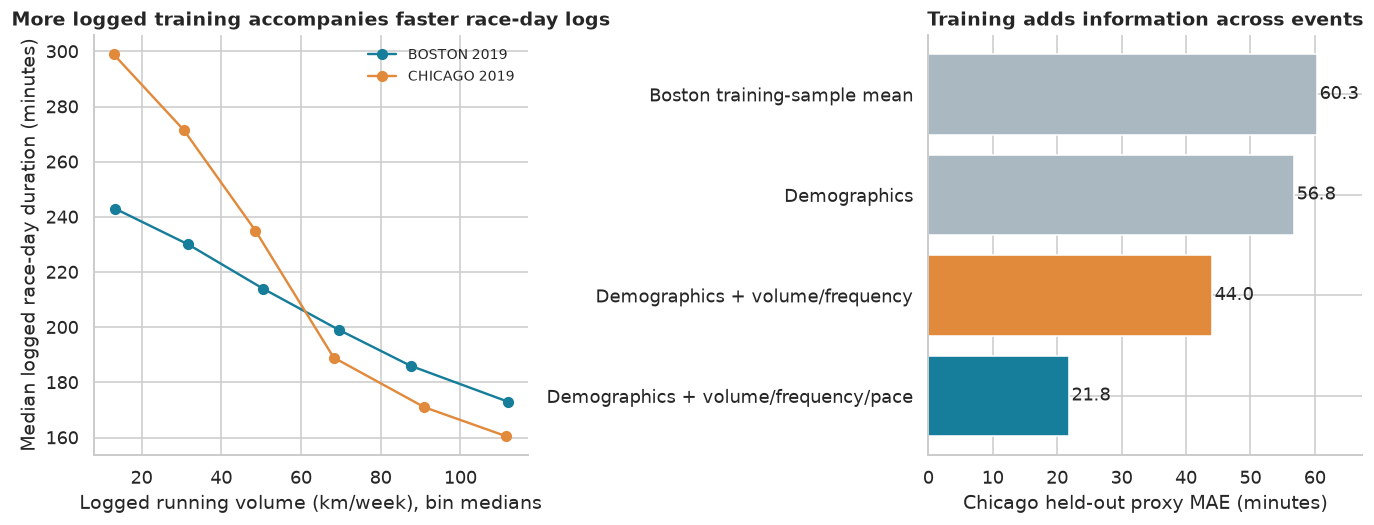

In [43]:
log_train=training_cohort.loc[training_cohort.race.eq('BOSTON 2019')].copy()
log_test_all=training_cohort.loc[training_cohort.race.eq('CHICAGO 2019')].copy()
log_test=log_test_all.loc[~log_test_all.athlete.isin(set(log_train.athlete))].copy()
assert set(log_train.athlete).isdisjoint(log_test.athlete)
training_predictions={'Boston training-sample mean':np.repeat(log_train.race_day_minutes.mean(),len(log_test))}
for label,numerics in [('Demographics',[]),('Demographics + volume/frequency',['weekly_km','days_per_week']),
                       ('Demographics + volume/frequency/pace',['weekly_km','days_per_week','training_pace'])]:
    # Linear model: simple enough to inspect; no test-set tuning.
    pre=ColumnTransformer([('cat',OneHotEncoder(drop='first',handle_unknown='error'),['gender','age_group']),
                           ('num','passthrough',numerics)])
    model=make_pipeline(pre,LinearRegression())
    columns=['gender','age_group']+numerics
    model.fit(log_train[columns],log_train.race_day_minutes)
    training_predictions[label]=model.predict(log_test[columns])
training_metrics=pd.DataFrame([{'model':label,'n_train':len(log_train),'n_test':len(log_test),
    'mae':mean_absolute_error(log_test.race_day_minutes,pred),
    'rmse':np.sqrt(mean_squared_error(log_test.race_day_minutes,pred)),
    'r2':r2_score(log_test.race_day_minutes,pred)} for label,pred in training_predictions.items()])
etable(training_metrics,'training_prediction');display(training_metrics)
fig,axes=plt.subplots(1,2,figsize=(12,4.7))
for race,color in [('BOSTON 2019','#167d9a'),('CHICAGO 2019','#e18a3b')]:
    subset=training_cohort.loc[training_cohort.race.eq(race)].copy()
    subset['volume_bin']=pd.cut(subset.weekly_km,[0,20,40,60,80,100,200],right=False)
    bins=subset.groupby('volume_bin',observed=True).agg(km=('weekly_km','median'),minutes=('race_day_minutes','median'),n=('athlete','size'))
    axes[0].plot(bins.km,bins.minutes,'o-',label=race,color=color)
axes[0].set(xlabel='Logged running volume (km/week), bin medians',ylabel='Median logged race-day duration (minutes)',
            title='More logged training accompanies faster race-day logs')
axes[0].legend(frameon=False,fontsize=9)
axes[1].barh(training_metrics.model,training_metrics.mae,color=['#aab8c2','#aab8c2','#e18a3b','#167d9a'])
axes[1].invert_yaxis()
axes[1].set(xlabel='Chicago held-out proxy MAE (minutes)',title='Training adds information across events')
for i,value in enumerate(training_metrics.mae):axes[1].text(value+.4,i,f'{value:.1f}',va='center')
axes[1].set_xlim(0,training_metrics.mae.max()+7)
fig.tight_layout();efigure('17_training_logs')

This source changes the answer to the classmates' training question: actual logged volume and running-day
frequency can be studied. It still does not establish what a prescribed mileage increase would cause.
Faster/healthier runners may train more, and unlogged activity remains unknown. The source was selected
from social-network users with major-marathon participation; age groups are coarse estimates.
The race-day outcome is a daily-log proxy, so the results should be treated as supplementary evidence
until matched to official finish records. We preserve that distinction in the report and do not mix
these prediction errors with the official-result models.

In [44]:
training_results={
    'source':training_manifest,'raw_daily_rows':training_raw_rows,'athletes':len(training_athletes),
    'window_rows':len(logs),'flagged_days':int(pre_logs.flagged.sum()),
    'cohort_rows':len(training_cohort),'cohort_athletes':int(training_cohort.athlete.nunique()),
    'audit':training_audit.to_dict(orient='records'),'summary':training_summary.to_dict(orient='records'),
    'effects':training_effects.to_dict(orient='records'),'metrics':training_metrics.to_dict(orient='records'),
    'overlapping_test_athletes_removed':len(log_test_all)-len(log_test),
    'volume_frequency_correlation':float(training_correlations.loc['weekly_km','days_per_week'])
}
(EXP/'training_results.json').write_text(json.dumps(training_results,indent=2,default=float)+'\n')
runpy.run_path(str(ROOT/'scripts/render_report.py'),run_name='__main__')
print('Completed six substantive datasets, the training-pilot audit, and the integrated report.')

Rendered integrated marathon_story.html.
Completed six substantive datasets, the training-pilot audit, and the integrated report.
